# M02c · Échantillons et estimation — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m02c_echantillons_estimation/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M02c.1 à M02c.10, M02c.13, M02c.14 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M02c.18 | La distribution des moyennes d'échantillons · `sample_means` | 🔨 | ★ | 20 |
|  | M02c.19 | Biais et erreur quadratique d'un estimateur, par simulation · `estimator_bias, estimator_mse` | 🔨 | ★★ | 25 |
|  | M02c.20 | Erreur type et intervalle de confiance · `standard_error, confidence_interval_mean` | 🔨 | ★ | 20 |
|  | M02c.21 | NumPy et SciPy : `ddof`, `np.percentile`, `scipy.stats.sem` | 📦 | ★ | 15 |
| B | M02c.22 | Prédire : l'histogramme des moyennes d'une loi exponentielle quand n grandit | 🔮 | ★ | 10 |
|  | M02c.23 | Couverture : 95 % des intervalles contiennent-ils la vraie moyenne ? | 🔬 | ★★ | 20 |
|  | M02c.24 | Grande dimension : le cube dont le centre est vide | 🔬 | ★★ | 20 |
|  | M02c.25 | Voir le théorème central limite : histogrammes et densité normale | 🎨 | ★ | 20 |
| C | M02c.26 | Chasse à l'erreur : un intervalle de confiance mal calculé | 🐛 | ★ | 15 |
|  | M02c.27 | Tester une fonction aléatoire : une tolérance en erreurs types | 🛠️ | ★ | 15 |
|  | M02c.28 | Défi : un intervalle à 95 % avec dix valeurs d'une loi asymétrique | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : statistiques descriptives, valeurs aberrantes, imputation, tirages sans remise, taille d'échantillon, théorème central limite, estimateurs, intervalles de confiance, covariance et matrice de covariance, percentile de latence, standardisation.
- Écrire les cinq fonctions de `mymath/estimation.py` et les tester, puis utiliser NumPy et SciPy.
- Prédire la distribution des moyennes, mesurer la couverture d'un intervalle et le volume en grande dimension, voir le théorème central limite, chasser des erreurs d'intervalle, tester une fonction aléatoire, construire un intervalle exact.

**Rappel express.** $\bar{x} = \frac{1}{n}\sum x_i$ ; $s^2 = \frac{1}{n - 1}\sum (x_i - \bar{x})^2$ (`ddof=1`) ; $\mathbb{E}[\bar{X}] = \mu$, $\sigma(\bar{X}) = \frac{\sigma}{\sqrt{n}}$ ; pour $n$ grand, $\bar{X} \approx \mathcal{N}\big(\mu, \frac{\sigma^2}{n}\big)$ ; $\text{EQM} = \text{biais}^2 + \text{variance}$ ; intervalle à 95 % : $\bar{x} \pm 1{,}96\,\frac{s}{\sqrt{n}}$ ; $\mathbb{V}(X + Y) = \mathbb{V}(X) + \mathbb{V}(Y) + 2\operatorname{Cov}(X, Y)$.

## Partie 0 · Vérifier tes exercices papier (✏️ M02c.1 à M02c.10, 🔗 M02c.13 et M02c.14)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"5/9"` ;
- une liste `[116.5, 124.5]`, `True` / `False`, ou une lettre entre guillemets, `"B"`.

Pour la loi normale, utilise la table de $\Phi$ de M02b (§3) : les réponses attendues sont arrondies de sorte que la table et un calcul exact donnent la même valeur. Les quantiles d'une série suivent la convention de la fiche (§1). Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements (Φ: the values of the table of M02b, §3)
import math
from fractions import Fraction

**Ex M02c.1 — Les statistiques d'une petite série : moyenne, médiane, quartiles, variance**

In [3]:
wbm.record("M02c.1a", 360 / 8, decimals=2, mistakes={"c'est la médiane ; la moyenne est la somme des valeurs divisée par leur nombre": 43.5, "divise la somme par le nombre de valeurs, 8": 360 / 7})
wbm.record("M02c.1b", (42 + 45) / 2, decimals=2, mistakes={"la médiane se lit sur la série triée": 42.5, "avec 8 valeurs, la médiane est la moyenne des deux valeurs du milieu": {42.0, 45.0}})
wbm.record("M02c.1c", 328, mistakes={"les carrés des écarts, pas les écarts : la somme des écarts vaut toujours 0": 0, "c'est la somme des carrés des valeurs ; il faut celle des carrés des écarts à la moyenne": 16528})
wbm.record("M02c.1d", 328 / 8, decimals=2, mistakes={"c'est la variance divisée par n − 1 ; ici, on divise par n": 328 / 7, "c'est un écart-type ; la variance est son carré": 41 ** 0.5})
wbm.record("M02c.1e", 328 / 7, decimals=3, mistakes={"c'est la variance divisée par n ; ici, on divise par n − 1": 41.0})
wbm.record("M02c.1f", 39 + 0.75 * (40 - 39), decimals=2, mistakes={"la convention de la fiche : position p(n − 1) dans la série triée numérotée à partir de 0, puis interpolation linéaire entre les deux voisines": {39.0, 39.25, 39.5, 40.0}})
wbm.record("M02c.1g", 47 + 0.25 * (51 - 47), decimals=2, mistakes={"la convention de la fiche : position p(n − 1) dans la série triée numérotée à partir de 0, puis interpolation linéaire entre les deux voisines": {47.0, 49.0, 50.0, 51.0}})
wbm.record("M02c.1h", 48 - 39.75, decimals=2, mistakes={"l'écart interquartile est Q3 − Q1, pas l'étendue": 20.0})

WBM_ANSWER {"coarse_any": {"0": ["37d06bb9cbece7669c1f3bd2de4c6078853ed455dfd62706bad740e639c64cd7"]}, "decimals": 2, "hash": "6dfc0be4581d60449380cf510ab99c4e1ed6d161cfac2f980d41baba4957b9ec", "hash_coarse": "44fc684ee5dd11b34ca7316cb918cfb6ff7bbad7f856c5efc5c009bc7688f753", "id": "M02c.1a", "kind": "float", "magnitude": 1, "mistakes": {"2233267919716f8704ac31c40700397aa2ffb09559316c1f9e6fe62111a942f9": "c'est la médiane ; la moyenne est la somme des valeurs divisée par leur nombre", "d38909e6c2750d3fc34bef884c0f6bdc709185a7e7f8afa475c84ac171e9c1b7": "divise la somme par le nombre de valeurs, 8"}, "sign": 1}
📝 Ex M02c.1a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["97514a0cffcadf8480e690226b71a802a7ca9d05108b3aba44580694439f7ccb"]}, "decimals": 2, "hash": "16be2420810b52bebdf7ba963ecdde082b9c27e456af221120712923113c3e84", "hash_coarse": "3a2b0496e596892ea8ee155020ba083d7150cf0cf5c7f809a87956c2570faf22", "id": "M02c.1b", "kind": "float", "magnitude": 1,

**Ex M02c.2 — z-scores, écart interquartile et valeurs aberrantes**

In [4]:
wbm.record("M02c.2a", 157 / 10, decimals=1, mistakes={"c'est la médiane ; la moyenne est la somme divisée par n": 14.0})
wbm.record("M02c.2b", (272.1 / 10) ** 0.5, decimals=3, mistakes={"l'énoncé demande s_n, qui divise par n": (272.1 / 9) ** 0.5, "c'est la variance ; l'écart-type est sa racine": 27.21})
wbm.record("M02c.2c", (31 - 15.7) / (272.1 / 10) ** 0.5, decimals=2, mistakes={"z = (x − x̄)/s : divise par l'écart-type, pas par la variance": 15.3 / 27.21, "l'énoncé demande s_n, qui divise par n": (31 - 15.7) / (272.1 / 9) ** 0.5})
wbm.record("M02c.2d", False, mistakes={"compare |z| de c) à 3": True})
wbm.record("M02c.2e", 13 + 0.25 * (14 - 13), decimals=2, mistakes={"la convention de la fiche : position p(n − 1) dans la série triée numérotée à partir de 0, puis interpolation linéaire": {13.0, 13.5, 14.0}})
wbm.record("M02c.2f", 15 + 1.5 * (15 - 13.25), decimals=3, mistakes={"c'est la barrière basse ; la barrière haute part de Q3": 13.25 - 1.5 * 1.75, "le facteur 1,5 multiplie l'écart interquartile": 15 + 1.75})
wbm.record("M02c.2g", True, mistakes={"compare 31 à la barrière de f)": False})
wbm.record("M02c.2h", (31 - 14) / (12 / 9) ** 0.5, decimals=1, mistakes={"avec la moyenne et l'écart-type des 9 autres valeurs, sans 31": (31 - 15.7) / (272.1 / 10) ** 0.5, "l'énoncé demande s_n, qui divise par le nombre de valeurs, ici 9": (31 - 14) / (12 / 8) ** 0.5})

WBM_ANSWER {"decimals": 1, "hash": "c9596b4e93624ca0fe8940ce5c80891b6cd3c5947068a84124d20bef22358d5a", "hash_coarse": "b352d8c5fb668cabda8dc2062ed6fb57eb98735d722f635ffafaff2d79774058", "id": "M02c.2a", "kind": "float", "magnitude": 1, "mistakes": {"1c46e03f44fc1a79a09c6f64782789adfc7eeefc676c70ec622bec85382197a3": "c'est la médiane ; la moyenne est la somme divisée par n"}, "sign": 1}
📝 Ex M02c.2a : réponse enregistrée (float, 1 décimale).
WBM_ANSWER {"coarse_any": {"0": ["e6f40248bcac92bd7e7f5ffda24497ccb1d20fbeb05cdc1bd89ec05cf7735683"]}, "coarser": {"1": ["b142959802112cd11fa5f1239db10488f7004343166cadb45a7a3df69609a7d6"]}, "decimals": 3, "hash": "cdad71b997afea8daab6c81f0f5331f9729ed545637347efa948aac738b90ee3", "hash_coarse": "d5c1f69f72637117fab5e2adaf68c1d16bb8406dcbb004c07258668a0c893f0e", "id": "M02c.2b", "kind": "float", "magnitude": 0, "mistakes": {"54ffd38bfdf8b62dc839a7e86ea46ff850a1e7782d2c45f26be9a92b07bd8638": "l'énoncé demande s_n, qui divise par n", "e54f8f714b230c4e

**Ex M02c.3 — Imputer par la moyenne ou la médiane : ce qui change**

In [5]:
wbm.record("M02c.3a", 60 / 6, decimals=2, mistakes={"la moyenne des 6 réponses : divise par 6": 60 / 8})
wbm.record("M02c.3b", (7 + 9) / 2, decimals=2, mistakes={"avec 6 valeurs, la médiane est la moyenne des deux valeurs du milieu": {7.0, 9.0}})
wbm.record("M02c.3c", 258 / 6, decimals=2, mistakes={"l'énoncé divise par le nombre de valeurs, n, pas par n − 1": 258 / 5})
wbm.record("M02c.3d", 80 / 8, decimals=2, mistakes={"une valeur manquante n'est pas un zéro : on la remplace par la moyenne": 60 / 8})
wbm.record("M02c.3e", 258 / 8, decimals=2, mistakes={"les deux valeurs imputées comptent : il y a maintenant 8 valeurs": 43.0})
wbm.record("M02c.3f", (6 / 8) ** 0.5, decimals=3, mistakes={"le rapport des écarts-types, pas celui des variances": 6 / 8})
wbm.record("M02c.3g", 76 / 8, decimals=2, mistakes={"on ajoute deux valeurs égales à la médiane, pas à la moyenne": 10.0})
wbm.record("M02c.3h", 8.0, decimals=2)

WBM_ANSWER {"coarse_any": {"0": ["1dca8fa1ecc27a8953cc938ee689065faac70e3d0a5e7b5677d6628afffb4caa"]}, "decimals": 2, "hash": "4900b463ee9063ea02a19cd9a445cf58142852cbcd51b3206c7d1b7f2f21c2ac", "hash_coarse": "987a5a92c44422e1658fb268bfa434ff3017801d282eb600aeb29da7ac2d06f1", "id": "M02c.3a", "kind": "float", "magnitude": 1, "mistakes": {"5ae8a58314da4684f0aeec4ff986ecf4f15460e746e1fbffe1b847148c62f701": "la moyenne des 6 réponses : divise par 6"}, "sign": 1}
📝 Ex M02c.3a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["50d0434e5c6ae6c451fdb29d13a5dad1ad731823e4ce9bbc98c110e5bcdacb63"]}, "decimals": 2, "hash": "c106732f3f15e64dccbb06358594579b16d2a506b8b54ed7279ab6626df96a69", "hash_coarse": "fac7632f4c84326d07f86f359f2768d1bf7fc3989a7bd4d08ec8336986967fd1", "id": "M02c.3b", "kind": "float", "magnitude": 0, "mistakes": {"5e9608bf044b7bb3a02548bc75e1099df7ebe04398fdf19491a162ee3e975ad6": "avec 6 valeurs, la médiane est la moyenne des deux valeurs du milieu",

**Ex M02c.4 — Avec ou sans remise : la variance de la moyenne**

In [6]:
wbm.record("M02c.4a", 8, mistakes={"c'est la variance d'une population : divise par N = 5": 10})
wbm.record("M02c.4b", 4, mistakes={"V(X̄) = σ²/n : la moyenne de n tirages varie moins qu'un tirage": 8, "σ²/n, pas σ²/n² : la somme a pour variance n σ²": 2})
wbm.record("M02c.4c", 10, mistakes={"sans tenir compte de l'ordre : chaque paire est comptée une fois": 20, "sans remise, une boule ne sort pas deux fois": 15})
wbm.record("M02c.4d", 6)
wbm.record("M02c.4e", 3, mistakes={"c'est la variance avec remise ; sans remise, les tirages sont dépendants": 4})
wbm.record("M02c.4f", -2, mistakes={"sans remise, un grand numéro tiré en laisse moins de grands : la covariance est négative": 2})
wbm.record("M02c.4g", Fraction(3, 4), kind="fraction", simplified=True, mistakes={"sans remise divisé par avec remise, dans cet ordre": "4/3"})
wbm.record("M02c.4h", (10_000 - 100) / (10_000 - 1), decimals=4, mistakes={"le dénominateur est N − 1, pas N": (10_000 - 100) / 10_000})

WBM_ANSWER {"hash": "b0292e42371b4b171bf67afff19e3b965e1b3317e8a19b79a5ae33166ff82ea5", "id": "M02c.4a", "kind": "int", "magnitude": 0, "mistakes": {"1a7b9a83d4ea0a4b6de12d934490a68b576584f492e8f65832858fa485730378": "c'est la variance d'une population : divise par N = 5"}, "sign": 1}
📝 Ex M02c.4a : réponse enregistrée (int).
WBM_ANSWER {"hash": "09396b18a67acef2de2d966531110e3de540f0b3cc722ff3eff8cfd506c7043c", "id": "M02c.4b", "kind": "int", "magnitude": 0, "mistakes": {"37624a045db61ce4e556845cd9e72927c2e3d2d74ec72d17525d6f09ebdd73bf": "σ²/n, pas σ²/n² : la somme a pour variance n σ²", "fbfed41f46e9d48c495328c0ffbdbb46ce1ca08dd1dea7bc48fcf0fc3821089a": "V(X̄) = σ²/n : la moyenne de n tirages varie moins qu'un tirage"}, "sign": 1}
📝 Ex M02c.4b : réponse enregistrée (int).
WBM_ANSWER {"hash": "c2c34636a06b3198cdfbae3970267066894618f779bf9eb632963d1dc26c8e0b", "id": "M02c.4c", "kind": "int", "magnitude": 1, "mistakes": {"a19ae0b2ec89cedbf2853224f4c52f105c3c11e93b0b93df48c93e3eb671f6b7"

WBM_ANSWER {"hash": "d4cfd31cf176610880e755fb7bf0ac80ece60df73fca34e1e090aea67529adc7", "id": "M02c.4g", "kind": "fraction", "mistakes": {"aeba89b2b47d66c2a0ed0a997d4e7dfeaed0bec622a7e25c22639faade2c6a5a": "sans remise divisé par avec remise, dans cet ordre"}, "sign": 1, "simplified": true}
📝 Ex M02c.4g : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["b04ae28ea182c65945dabdbeb869ef45d2762efa312ac212a653361bc4a19a64"], "1": ["96d7a52fd61465fbaa794ad1f6c152e3f0b52d550b439e7e8d8aa1ed7b205f87"]}, "coarser": {"2": ["6c65adfe464793686d3ef2b820378e60ccf4047e1b0d8c9cfa2dfd6fa8cc6ec0"]}, "decimals": 4, "hash": "8525f9bbdec8a337a87a0614bb4c84182e2accceb85d4a6a62c0e4924a556d86", "hash_coarse": "96c2e8f14564e67f30880fad589b72128b9ad268f4ba6411a981e17e0dc66f86", "id": "M02c.4h", "kind": "float", "magnitude": -1, "mistakes": {"10561c0f6a59d6f604a68e5e171838ee7de3ce90c2fbb5c287540ad8db6f18bb": "le dénominateur est N − 1, pas N"}, "sign": 1}
📝 Ex M02c.4h : réponse enregistrée (float

**Ex M02c.5 — Combien d'observations pour une moyenne précise à 1 % ?**

In [7]:
wbm.record("M02c.5a", 2 / 16 ** 0.5, decimals=2, mistakes={"l'écart-type de la moyenne divise σ par √n, pas par n": 2 / 16})
wbm.record("M02c.5b", 1.96 * 2 / 16 ** 0.5, decimals=2, mistakes={"c'est l'écart-type de X̄ ; à 95 %, la demi-largeur le multiplie par le quantile de la loi normale": 0.5})
wbm.record("M02c.5c", 62, fractional="le plus petit entier qui convient : l'arrondi supérieur, pas l'arrondi le plus proche.", mistakes={"avec ce n, la demi-largeur dépasse encore 0,5 W": 61})
wbm.record("M02c.5d", 4 / (62 * 0.5 ** 2), decimals=3, mistakes={"Bienaymé-Tchebychev utilise la variance σ², pas l'écart-type": 2 / (62 * 0.25)})
wbm.record("M02c.5e", 320, fractional="le plus petit entier qui convient : l'arrondi supérieur, pas l'arrondi le plus proche.")
wbm.record("M02c.5f", 4, mistakes={"la demi-largeur varie en 1/√n, pas en 1/n": 2})
wbm.record("M02c.5g", 2 / 400 ** 0.5, decimals=2, mistakes={"l'écart-type de la moyenne divise σ par √n, pas par n": 2 / 400})
wbm.record("M02c.5h", 246, fractional="le plus petit entier qui convient : l'arrondi supérieur, pas l'arrondi le plus proche.", mistakes={"avec ce n, la demi-largeur dépasse encore 0,5 W": 245, "recalcule avec σ = 4 W": 62})

WBM_ANSWER {"decimals": 2, "hash": "b669cc6ac22e356088dd6e562536cc3104c14263416a2fd44e79d6ea2a2bc3d7", "hash_coarse": "4553cb1f8186a5d2f9d09a48faedd455cf62a106f9efacbdb50fb27f2b566b5f", "id": "M02c.5a", "kind": "float", "magnitude": -1, "mistakes": {"6d3773c720c47180171c7b3fd95cd86fad386b9cbdf5907ef0e06fb03731fe60": "l'écart-type de la moyenne divise σ par √n, pas par n"}, "sign": 1}
📝 Ex M02c.5a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["18cf62f34ce6c6d04978ce32224bbe975c9e5a045277ff647119ff40dadc3a9c"]}, "decimals": 2, "hash": "78390af9383e8c5f612f94d3fd50adc7e6016842e1eb3f60e313ac0f73fa447d", "hash_coarse": "8d562d292d51ca34e0f213ceec912088f41f1cc32085c0b1c3594bbd0334a8f2", "id": "M02c.5b", "kind": "float", "magnitude": -1, "mistakes": {"3b8072775cc5f9fd919be606158a2cdf2694054adb6f83fa968b4e43e0ff4fb5": "c'est l'écart-type de X̄ ; à 95 %, la demi-largeur le multiplie par le quantile de la loi normale"}, "sign": 1}
📝 Ex M02c.5b : réponse enregistrée

**Ex M02c.6 — Le théorème central limite à la main : une somme de 100 variables**

In [8]:
wbm.record("M02c.6a", -1 * 0.5 + 0 * 0.3 + 4 * 0.2, decimals=2, mistakes={"pondère chaque valeur par sa probabilité": 1.0})
wbm.record("M02c.6b", (1 * 0.5 + 16 * 0.2) - 0.3 ** 2, decimals=2, mistakes={"V(X) = E[X²] − E[X]² : retire le carré de l'espérance": 3.7, "c'est l'écart-type ; la variance est son carré": 1.9})
wbm.record("M02c.6c", 100 * 0.3, decimals=1, mistakes={"S additionne 100 jours : la linéarité de l'espérance": 0.3})
wbm.record("M02c.6d", (100 * 3.61) ** 0.5, decimals=1, mistakes={"les variances s'additionnent, pas les écarts-types": 190.0, "c'est la variance de S ; l'écart-type est sa racine": 361.0})
wbm.record("M02c.6e", 1 - 0.8413, decimals=4, mistakes={"c'est P(S ≤ 49) ; P(S > 49) est l'événement contraire": 0.8413})
wbm.record("M02c.6f", 2 * 0.8413 - 1, decimals=3, mistakes={"l'événement a deux côtés de l'espérance : retire la queue de gauche aussi": 0.8413})
wbm.record("M02c.6g", 1.9 / 10, decimals=2, mistakes={"c'est σ(S) ; le gain moyen divise S par 100": 19.0, "l'écart-type d'une moyenne divise σ par √n, pas par n": 1.9 / 100})
wbm.record("M02c.6h", 155, fractional="le plus petit entier qui convient : l'arrondi supérieur, pas l'arrondi le plus proche.", mistakes={"avec ce n, la probabilité reste un peu sous 0,975": 154})

WBM_ANSWER {"decimals": 2, "hash": "b44bc02b567f467f3288745fc956cdee1baf74ac7a56a2fe5ca507817d731d9f", "hash_coarse": "4f468bdecc7ed26fb8c984425c6fef8f36d4a502b09312f9b65bc36589ba0c11", "id": "M02c.6a", "kind": "float", "magnitude": -1, "mistakes": {"048af76b99292df8e9fb7b1ca48c4b20c560ab879079ba35a53027cd7a5acb1d": "pondère chaque valeur par sa probabilité"}, "sign": 1}
📝 Ex M02c.6a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["4777ea587847f1e5596fc969126e7916e4a305da647c6a2a1c88b17e36109178"]}, "decimals": 2, "hash": "8b828946f4886b3bf25f2706a6287a153a0071d59d0fb9e8409517ede1a78642", "hash_coarse": "09f9d06408d0545be981a141c41c5cd5fc33d299ece9237636e92cdbaed2eaaf", "id": "M02c.6b", "kind": "float", "magnitude": 0, "mistakes": {"0be486860d0943ab4837d7334df5d17b398b45f7cc16959436a2010e113a7349": "V(X) = E[X²] − E[X]² : retire le carré de l'espérance", "80025e3f7468f4cca41b1ee82b3fab992eedeccd6f66fc82d83c150807664335": "c'est l'écart-type ; la variance es

**Ex M02c.7 — Biais, variance et erreur quadratique de trois estimateurs**

In [9]:
wbm.record("M02c.7a", 3 * 6 / 4 - 6, decimals=2, mistakes={"le biais est E[T₃] − μ, dans cet ordre": 1.5, "le biais est E[T₃] − μ, pas E[T₃]": 4.5})
wbm.record("M02c.7b", 3, mistakes={"V(T₂) n'est pas σ² : la moyenne de trois variables indépendantes varie moins": 9, "V(X₁ + X₂ + X₃) = 3σ², puis V(aY) = a² V(Y)": 1})
wbm.record("M02c.7c", Fraction(27, 16), kind="fraction", simplified=True, mistakes={"la somme contient trois variables de variance σ²": "9/16", "diviser par 4 divise la variance par 4²": "27/4"})
wbm.record("M02c.7d", 1.5 ** 2 + 27 / 16, decimals=4, mistakes={"EQM = biais² + variance : le biais compte au carré": 27 / 16 + 1.5, "EQM = biais² + variance : les deux s'additionnent": 27 / 16 - 1.5 ** 2})
wbm.record("M02c.7e", 2, mistakes={"compare l'EQM de T₃ (d) à celle de T₂, qui est sans biais": 3})
wbm.record("M02c.7f", 0.5 ** 2 + 27 / 16, decimals=4, mistakes={"recalcule le biais de T₃ avec μ = 2": 1.5 ** 2 + 27 / 16})
wbm.record("M02c.7g", 3, mistakes={"recalcule l'EQM de T₃ avec μ = 2, puis compare-la à celle de T₂": 2})
wbm.record("M02c.7h", 21 ** 0.5, decimals=3, mistakes={"c'est m² ; la question demande m": 21.0})

WBM_ANSWER {"coarse_any": {"0": ["54988fd5ec3c62ecb75afb7adcab299b739758a2755b29b2eee353a2ab6efa89"]}, "decimals": 2, "hash": "2df2fdbd8511410af9ff50a76a54b4c103365c4a13305546ba36aa3915075ca7", "hash_coarse": "d90d2552d4a9773536fd9b7d0eb179f0cb21ac6f4651e4a9ef313a6622266ed1", "id": "M02c.7a", "kind": "float", "magnitude": 0, "mistakes": {"385767f6f7de10ea2b3af431c2de9d154b347ff0243005315e7452908c8a7068": "le biais est E[T₃] − μ, pas E[T₃]", "6459bff7174793aeb5187d786e8af77238e8e7b9c995135cd6aab22d37bd944b": "le biais est E[T₃] − μ, dans cet ordre"}, "sign": -1}
📝 Ex M02c.7a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"hash": "3725d33d43c53b30eaf587a9256e2510ec6594b609d85b8838254af983c685ae", "id": "M02c.7b", "kind": "int", "magnitude": 0, "mistakes": {"4f946ea85f023f855ec5fc6ca2704f9e5eebf87e69e71184216947c6a25dbdb8": "V(X₁ + X₂ + X₃) = 3σ², puis V(aY) = a² V(Y)", "8aca023d878103840de703354d9eac5daf1b6371a53998fe6c053d1590ca085d": "V(T₂) n'est pas σ² : la moyenne de trois v

**Ex M02c.8 — Erreur type et intervalle de confiance d'une moyenne**

In [10]:
wbm.record("M02c.8a", 14 / 49 ** 0.5, decimals=2, mistakes={"l'erreur type divise s par √n, pas par n": 14 / 49})
wbm.record("M02c.8b", [120.5 - 1.96 * 2, 120.5 + 1.96 * 2], decimals=2, mistakes={"l'intervalle utilise l'erreur type de a), pas l'écart-type des données": [120.5 - 1.96 * 14, 120.5 + 1.96 * 14], "à 95 %, la demi-largeur multiplie l'erreur type par le quantile de la loi normale": [118.5, 122.5]})
wbm.record("M02c.8c", 2 * 1.96 * 2, decimals=2, mistakes={"c'est la demi-largeur ; la largeur va de la borne basse à la borne haute": 3.92})
wbm.record("M02c.8d", 1.645 * 2, decimals=2, mistakes={"à 90 %, le quantile n'est pas celui de 95 %": 3.92})
wbm.record("M02c.8e", 189, fractional="le plus petit entier qui convient : l'arrondi supérieur, pas l'arrondi le plus proche.", mistakes={"avec ce n, la demi-largeur dépasse encore 2 ms": 188})
wbm.record("M02c.8f", (0.9 * 0.1 / 400) ** 0.5, decimals=3, mistakes={"l'erreur type est la racine de p̂(1 − p̂)/n": 0.9 * 0.1 / 400})
wbm.record("M02c.8g", 1.96 * (0.9 * 0.1 / 400) ** 0.5, decimals=4, mistakes={"c'est l'erreur type ; la demi-largeur à 95 % la multiplie par le quantile": 0.015})
wbm.record("M02c.8h", False, mistakes={"compare 0,02 à la demi-largeur de g)": True})

WBM_ANSWER {"coarse_any": {"0": ["129ef81f6ae8938b42b7fb9c118581aa04672a539f14fbe732cabf303e915d2e"]}, "decimals": 2, "hash": "ebfef8c63af5d728449beac71203f234c16324b1183b6f3e619c3daef3210b15", "hash_coarse": "4634ec074c0b28ded355cb3fef25872ad5119072cba247519944a73d8a78b447", "id": "M02c.8a", "kind": "float", "magnitude": 0, "mistakes": {"eee84ae5a9a4ae737a72af3c5378b5f2e333d9df10d485b336af7cdafbd45f71": "l'erreur type divise s par √n, pas par n"}, "sign": 1}
📝 Ex M02c.8a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 2, "element_coarse": [["2c898f29608bdbfcbb4b58ff9b032d74a67373bd85a1781b71c5fd35866ad35e"], ["5acce41c21123b48a452762a6649dc34c6c784f3b1b50e2492028d6e32d28c36"]], "element_coarse_any": [["776b73b9af10b9fa33e9508fab97b78f3bf48be633d5ff9cf7d3d8b907ccb64d"], ["28038e197641592cd67690e86b086bf8321c2aaf83fbc097d18278355d489ae3"]], "element_hashes": ["fcac99606f5d572ec9ecb86b1a59456367d5b40f9e364a4677a5373a82cef28d", "b0039c19670b40bdff1a11a2ceb34bcd97b84bfc

**Ex M02c.9 — La variance d'une somme et la covariance : V(X + Y), V(X − Y)**

In [11]:
wbm.record("M02c.9a", 3 / (4 ** 0.5 * 9 ** 0.5), decimals=2, mistakes={"ρ divise la covariance par le produit des écarts-types, pas des variances": 3 / 36})
wbm.record("M02c.9b", 4 + 9 + 2 * 3, mistakes={"n'oublie pas le terme de covariance": 13, "le terme de covariance compte deux fois": 16})
wbm.record("M02c.9c", 4 + 9 - 2 * 3, mistakes={"V(Y) s'ajoute aussi pour une différence : une variance n'est jamais retranchée": {1, -11, -5}, "pour une différence, le terme de covariance change de signe": 19})
wbm.record("M02c.9d", 4 * 4 + 9 - 2 * 2 * 3, mistakes={"V(2X) = 4 V(X) : le facteur compte au carré": 5, "le terme de covariance porte le produit des deux coefficients, ici négatif": 37})
wbm.record("M02c.9e", 2 * 3, mistakes={"Cov(aX, Y) = a Cov(X, Y) : le facteur compte": 3, "le facteur compte une fois, pas au carré": 12})
wbm.record("M02c.9f", 16 / 4, decimals=2, mistakes={"la moyenne des produits des écarts : divise leur somme par n = 4": 16.0, "l'énoncé divise par n = 4, pas par n − 1": 16 / 3})
wbm.record("M02c.9g", 4 / (2.5 * 7.5) ** 0.5, decimals=3, mistakes={"r divise la covariance par le produit des écarts-types, pas des variances": 4 / (2.5 * 7.5)})
wbm.record("M02c.9h", 2.5 + 7.5 + 2 * 4, decimals=2, mistakes={"n'oublie pas le terme de covariance": 10.0})

WBM_ANSWER {"decimals": 2, "hash": "570869e62d0563eb149100baf3465795ae452b1b93217c99ac0bdfd01759dfe0", "hash_coarse": "e929fe2226adc6d66d1f47ff6c9ccf1f8d7f006f3be6b55b7150ebd3e98948ae", "id": "M02c.9a", "kind": "float", "magnitude": -1, "mistakes": {"237527147d3f306b78124e1868e9c0e82f83eaee930082b23e08a9fe3ed7a51f": "ρ divise la covariance par le produit des écarts-types, pas des variances"}, "sign": 1}
📝 Ex M02c.9a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"hash": "4535e645ff0028beb4da5842e7fa0976c6f4521a784e982b227583d9363a2177", "id": "M02c.9b", "kind": "int", "magnitude": 1, "mistakes": {"b146dc9760fa8bc2777a59b8c4a39724c8385e5005ea5434c81694c0dfac0adc": "n'oublie pas le terme de covariance", "c629e0affb4fcfac306994e97f40bc6df825cca55c444f1cf67e43c5e167b3ed": "le terme de covariance compte deux fois"}, "sign": 1}
📝 Ex M02c.9b : réponse enregistrée (int).
WBM_ANSWER {"hash": "b69ad2e6f78420f8057a0e780c9d8d303612b6c85a69ffe24f66eb99a1452d40", "id": "M02c.9c", "kind": "i

**Ex M02c.10 — La matrice de covariance de trois variables : la lire et la vérifier**

In [12]:
wbm.record("M02c.10a", 9, mistakes={"la diagonale contient les variances, pas les écarts-types": 3})
wbm.record("M02c.10b", -1)
wbm.record("M02c.10c", Fraction(1, 3), kind="fraction", simplified=True, mistakes={"la corrélation divise par le produit des écarts-types, racines des variances": "1/18"})
wbm.record("M02c.10d", True, mistakes={"lis la case de la ligne 2, colonne 3": False})
wbm.record("M02c.10e", 16, mistakes={"les covariances comptent, et chacune deux fois (Σᵢⱼ et Σⱼᵢ)": {14, 15}})
wbm.record("M02c.10f", 7, mistakes={"le terme −2 Cov(X₁, X₃) change de signe quand la covariance est négative": 3, "une différence ajoute aussi la variance de X₃": 5})
wbm.record("M02c.10g", "B", mistakes={"vérifie pour chaque tableau la symétrie, puis que la corrélation reste entre −1 et 1": {"A", "C"}})
wbm.record("M02c.10h", 9, mistakes={"n'oublie pas les termes hors de la diagonale (i ≠ j)": 17})

WBM_ANSWER {"hash": "e6368248c1461736656ab5a8d946864d5344c9e060be6fb36be83c17353a1535", "id": "M02c.10a", "kind": "int", "magnitude": 0, "mistakes": {"a48bf9ed9d7a78ee306ad0569d2afda051f5afa87479150b4e92539fa138d259": "la diagonale contient les variances, pas les écarts-types"}, "sign": 1}
📝 Ex M02c.10a : réponse enregistrée (int).
WBM_ANSWER {"hash": "1ef9e370700aa24c51a946f136a72bc0059b2838a6dc34c66c3fe88e302289ae", "id": "M02c.10b", "kind": "int", "magnitude": 0, "sign": -1}
📝 Ex M02c.10b : réponse enregistrée (int).
WBM_ANSWER {"hash": "b4eb67c5625ab59a26d7d0affa7a08d5684177c8198abe02c7f88293cd7b448f", "id": "M02c.10c", "kind": "fraction", "mistakes": {"e83b9a3259b7c7484541f5415ea82459a7d8f050798cee5e5461fa9f82fddc2e": "la corrélation divise par le produit des écarts-types, racines des variances"}, "sign": 1, "simplified": true}
📝 Ex M02c.10c : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "ff4816dd722042793de1335365d86e6c191b87c6e315c5adc7671e173e948e40", "id": "M02c.10d", "

**Ex M02c.13 — Le 99e percentile d'une latence : l'estimer et dire son incertitude**

In [13]:
wbm.record("M02c.13a", 0.99 * 999, decimals=2, mistakes={"la convention de la fiche : h = p(n − 1), avec n − 1 = 999": 990.0})
wbm.record("M02c.13b", 179 + 0.01 * (182 - 179), decimals=2, mistakes={"interpole entre les deux valeurs qui encadrent la position h": {179.0, 182.0}})
wbm.record("M02c.13c", 290 + 0.001 * (412 - 290), decimals=3, mistakes={"interpole entre les deux valeurs qui encadrent la position h": {290.0, 412.0}})
wbm.record("M02c.13d", 10, mistakes={"compte les mesures au-dessus du quantile, pas en dessous": 990})
wbm.record("M02c.13e", (1000 * 0.01 * 0.99) ** 0.5, decimals=3, mistakes={"c'est la variance ; l'écart-type est sa racine": 9.9, "la binomiale a pour variance n p (1 − p)": 10 ** 0.5})
wbm.record("M02c.13f", -40 * math.log(0.01), decimals=2, mistakes={"la loi exponentielle d'espérance 40 a pour paramètre λ = 1/40": -math.log(0.01) / 40, "au-dessus de q_0,99, il reste 1 % des valeurs, pas 99 %": -40 * math.log(0.99)})
wbm.record("M02c.13g", 10_000, mistakes={"au-dessus de q_0,999, il y a 0,1 % des mesures, pas 1 %": 1000})

WBM_ANSWER {"coarse_any": {"0": ["502dda5ca1ea12531947b3878ce7b0f4c645f175adf2925545d980589cefb3ed"]}, "decimals": 2, "hash": "677d0a692dfd24619da110e8cc7b72d6093122d95771434e116d2f6eddb62eb4", "hash_coarse": "f90aefa8f34cd8e960e165f8ed1b718f657a60018dc8676018d3dc292ef45e55", "id": "M02c.13a", "kind": "float", "magnitude": 2, "mistakes": {"44af3c37e9da59cba68873a9d482a1557295a238c40d27ef42260d0025e6ad4b": "la convention de la fiche : h = p(n − 1), avec n − 1 = 999"}, "sign": 1}
📝 Ex M02c.13a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["67dc4b01711e26c71dd02d2801fe921c7df4d2fb6500025ea40a9ef0e00758a2"]}, "decimals": 2, "hash": "c51ae921e4afe703c3a295f4ebc4e455461d94fec7898de26176613499c48536", "hash_coarse": "d631d6665c156f5127f4defe92b2ab4e451ea975972fb43b5bec085efe9d1079", "id": "M02c.13b", "kind": "float", "magnitude": 2, "mistakes": {"4f4c0e71c0bf0293fd6c20f15ae2357976d589d65a78808831bf990910c81fb0": "interpole entre les deux valeurs qui encadrent la

**Ex M02c.14 — Standardiser des features avec les statistiques du seul train**

In [14]:
wbm.record("M02c.14a", 70 / 5, decimals=2)
wbm.record("M02c.14b", 8 ** 0.5, decimals=3, mistakes={"l'énoncé demande s_n, qui divise par n": 10 ** 0.5, "c'est la variance ; l'écart-type est sa racine": 8.0})
wbm.record("M02c.14c", (20 - 14) / 8 ** 0.5, decimals=3, mistakes={"standardise avec la moyenne et l'écart-type du jeu d'entraînement": (20 - 103 / 7) / 3.238795442501324})
wbm.record("M02c.14d", (13 - 14) / 8 ** 0.5, decimals=3, mistakes={"13 est sous la moyenne du train : son z-score est négatif": 1 / 8 ** 0.5})
wbm.record("M02c.14e", 103 / 7, decimals=3, mistakes={"la moyenne des 7 valeurs, train et test réunis": 14.0})
wbm.record("M02c.14f", (20 - 103 / 7) / 3.238795442501324, decimals=3, mistakes={"cette fois, la moyenne et l'écart-type des 7 valeurs": (20 - 14) / 8 ** 0.5})
wbm.record("M02c.14g", 0.0, decimals=2)

WBM_ANSWER {"coarse_any": {"0": ["d2faac933afe8223ea0d3ce3e590eeffdfb9cddb749cdaa738a93205a201abbd"]}, "decimals": 2, "hash": "4f11a841ee437c2a3dbcb3f354054cb7f714aa28608293f4f85783a0edfb2e46", "hash_coarse": "b37d2da0c1d4b0f14b5b2d85e4739cc499d3d67943c0a09090a5e627b367d57b", "id": "M02c.14a", "kind": "float", "magnitude": 1, "sign": 1}
📝 Ex M02c.14a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["035506096580ae4182e42fb05d3ee4c3254a0d1bc0b0e23585f0634b00e4e014"]}, "coarser": {"1": ["aa40b75527679622f98a4ac31b205be1ced8ebd29e97794336ad73549377323b"]}, "decimals": 3, "hash": "0eb1b9426586e3cfa85cc6e7df003e77ed7e75ad8df01d492e20286bf622ddd2", "hash_coarse": "09a9de2139aad348361a68a7be50d281bb30e79378b2c32e03aa673b674e5eba", "id": "M02c.14b", "kind": "float", "magnitude": 0, "mistakes": {"6dcf4b1d0d342f2dd9f3ff1b45e9105b68a54df539bb9308260b41d91597b8eb": "l'énoncé demande s_n, qui divise par n", "a600a794df59d8f4324d733711dc802babe381b2f10f9a11f6b8e12fbacc786

## Partie A · Ta librairie : moyennes d'échantillons, biais, erreur type et intervalle de confiance

Fiche §3 à §7. Les cinq fonctions de `mymath/estimation.py`, puis les mêmes statistiques avec NumPy et SciPy.

In [15]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from wbm.nbtools import checked, drawn, run_pytest_group, verdict


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M02c.18 — La distribution des moyennes d'échantillons · `sample_means` 🔨 ★ ⏱️ 20 min
**Objectif :** simuler beaucoup d'échantillons, calculer leurs moyennes, et vérifier la loi des grands nombres et le théorème central limite sur ces moyennes.  
**Prérequis :** fiche §3 à §5 · **mymath :** `estimation.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M02b). Ouvre ta copie `mon_travail/mymath/estimation.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy est permis (importe-le en haut du fichier), `scipy.stats` non : les tests comparent tes résultats à lui, et un test vérifie que tu ne t'en sers pas. Le hasard vient toujours d'**un seul** générateur `np.random.default_rng(seed)`, créé une fois au début de la fonction, et utilisé dans l'ordre que dit la docstring : c'est ce qui rend tes résultats identiques à ceux de la référence. Chaque nombre renvoyé est un `float` de Python (`float(...)` convertit un nombre de NumPy).

Écris `sample_means(draw, n, repeats, seed=0)` : un générateur `rng = np.random.default_rng(seed)`, puis `repeats` appels `draw(rng, n)`, **l'un après l'autre**, et la moyenne de chaque échantillon, dans un array NumPy de forme `(repeats,)`. `draw` peut renvoyer une liste ou un array. $n < 1$ ou `repeats` $< 1$ lèvent une `ValueError`.

Dans la vérification, `expo` tire $n$ valeurs de la loi exponentielle d'espérance 2 (`rng.exponential(2.0, n)`, d'écart-type 2 aussi), et `die` $n$ lancers d'un dé à 6 faces. La vérification calcule :
- a) la liste des 3 moyennes de `sample_means(die, 4, 3, seed=5)` (2 décimales) ;
- b) la longueur de `sample_means(expo, 10, 500)` (un entier) ;
- c) la moyenne des 20 000 moyennes de `sample_means(expo, 5, 20_000)` (2 décimales) ;
- d) leur écart-type (`np.std` ; 2 décimales) ;
- e) l'écart-type des 20 000 moyennes de 20 valeurs, divisé par celui de d) (2 décimales) ;
- f) le nom de l'erreur levée par `sample_means(expo, 3, 0)` ;
- g) le nom du type du résultat, en texte (`type(...).__name__`) ;
- h) la proportion des 20 000 moyennes de 30 valeurs qui tombent dans $2 \pm 1{,}96\,\frac{2}{\sqrt{30}}$ (2 décimales).

Dans ta copie : compare c), d), e) et h) à ce que prévoient les §3 et §5 de la fiche ($\mu$, $\frac{\sigma}{\sqrt{n}}$, $\sqrt{\frac{5}{20}}$, 0,95).

In [16]:
mymath = wbm.load_mymath("ref")
sample_means = mymath.estimation.sample_means
expo = lambda rng, n: rng.exponential(2.0, n)      # mean 2, standard deviation 2
die = lambda rng, n: rng.integers(1, 7, n)          # n throws of a six-sided die
m5, m20, m30 = (sample_means(expo, n, 20_000) for n in (5, 20, 30))
print("a)", list(sample_means(die, 4, 3, seed=5)), " b)", len(sample_means(expo, 10, 500)),
      " c)", m5.mean(), " d)", m5.std(), "theory:", 2 / math.sqrt(5))
print("e)", m20.std() / m5.std(), "theory:", math.sqrt(5 / 20), " f)", raised(sample_means, expo, 3, 0),
      " g)", type(sample_means(expo, 3, 4)).__name__,
      " h)", np.mean(np.abs(m30 - 2) <= 1.96 * 2 / math.sqrt(30)))

a) [np.float64(4.0), np.float64(3.25), np.float64(3.0)]  b) 500  c) 1.9944702796478537  d) 0.8991258266515022 theory: 0.8944271909999159
e) 0.5009572314684468 theory: 0.5  f) ValueError  g) ndarray  h) 0.9489


In [17]:
wbm.record("M02c.18a", [4.0, 3.25, 3.0], decimals=2,
           mistakes={"un seul générateur pour tous les échantillons : np.random.default_rng(seed) une fois, avant la "
                      "boucle": [4.0, 4.0, 4.0],
                     "le générateur reçoit la graine passée en argument (seed)": [4.0, 1.25, 4.25]})
wbm.record("M02c.18b", 500)
wbm.record("M02c.18c", 1.994470280, decimals=2,
           mistakes={"la moyenne de chaque échantillon, pas sa somme : divise par n": 9.972351398})
wbm.record("M02c.18d", 0.899125827, decimals=2,
           mistakes={"la moyenne de chaque échantillon, pas sa somme : divise par n": 4.495629133})
wbm.record("M02c.18e", 0.500957231, decimals=2)
wbm.record("M02c.18f", "ValueError",
           mistakes={"repeats = 0 : aucun échantillon, lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M02c.18g", "ndarray",
           mistakes={"la docstring demande un array NumPy : np.array(...) ou np.asarray(...)": {"list", "tuple"}})
wbm.record("M02c.18h", 0.9489, decimals=2)

WBM_ANSWER {"decimals": 2, "element_coarse": [["a63ff945143164eb045deb736522b9fb4b19f52343dd246dd0e62c09a66400e2"], ["25986ba0692853d47983eb828a272de00e64c76fd7a24fe8dea3f4e226c9f3bb", "64194780fe3875c84b8cf98cc8c7b8e925778e0df53f69e8aa3c976aa9485a4c"], ["f0413063a1b5e3526acf9009d5bd7486e4eb94a8635143f9fa3cdfb190d7a247"]], "element_coarse_any": [["c4207aab03ea15f857b85a2c8b46f18a830dfa6293e1e267c0989542b791f388"], ["5b6fb22875aaf7398b0ad2bd7d5d578f4cb50d27ef3f2e8717618d18fddaa700"], ["fd180b42a2f7b96425e937b8d50919b02b8f4a51ad596fc1148f9f6e5efadc1c"]], "element_hashes": ["de63d03f23378c305f327b2d1c27396f09b3c6e5b6dcc6d6d7d907b8d115d00f", "f76a236dc0117f1fabbe6399cc53916ed20d6fe7956df7a1031a92b86340ca51", "d17728a2647bc2ee178c10b3165620e0009ebdd1b18751048530646691bd1cb3"], "hash": "3810136d4b13bf14949af73894fdfd0b5c2229892146d43361efbf439ef997d4", "id": "M02c.18a", "kind": "array", "mistakes": {"6c85ae7095ce4dacc8a16c7776a1c980d5b7cee6d5c96a9681860e1ccf36b152": "le générateur reçoit la 

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [18]:
run_pytest_group("tests/test_m02c_estimation.py", "test_sample_means_ or test_estimation_uses", impl="ref")

pytest: 12 réussi(s), 32 non sélectionné(s) en 0,31 s


💡 c) 1,99 pour $\mu = 2$ ; d) 0,90 pour $\frac{2}{\sqrt{5}} \approx 0{,}894$ ; e) 0,50 pour $\sqrt{\frac{5}{20}} = \frac{1}{2}$ : quatre fois plus de valeurs divisent l'écart-type par 2. h) 0,949 pour 0,95 : avec 30 valeurs d'une loi pourtant très asymétrique, la loi normale prédit déjà bien la proportion. La boucle `for` sur les échantillons est permise ici : 20 000 appels prennent moins d'une seconde.

### Ex M02c.19 — Biais et erreur quadratique d'un estimateur, par simulation · `estimator_bias, estimator_mse` 🔨 ★★ ⏱️ 25 min
**Objectif :** mesurer par simulation le biais et l'erreur quadratique d'un estimateur, et retrouver ceux des deux variances de l'échantillon.  
**Prérequis :** fiche §6 · **mymath :** `estimation.py` · **Parcours :** C

Écris `estimator_bias(estimator, draw_sample, true_value, repeats, seed=0)` et `estimator_mse(...)` (fiche §6) : un générateur `np.random.default_rng(seed)`, `repeats` échantillons `draw_sample(rng)` tirés l'un après l'autre, l'estimation `estimator(sample)` de chacun, puis la moyenne des estimations moins `true_value` (le biais), ou la moyenne des carrés des erreurs (l'erreur quadratique). Avec la même graine, les deux fonctions voient les mêmes échantillons : une fonction auxiliaire commune, `_estimates(...)`, évite d'écrire deux fois la simulation. `repeats` $< 1$ lève une `ValueError`.

Dans la vérification, `normal_5` tire 5 valeurs de $\mathcal{N}(0, 2^2)$ (donc $\sigma^2 = 4$), `var_0` est la variance divisée par $n$ et `var_1` la variance divisée par $n - 1$ ; `uniform_5` tire 5 valeurs uniformes sur $[0 ; 10]$. Avec `repeats = 20_000` et la graine par défaut, la vérification calcule :
- a) le biais de `var_0` (2 décimales) ;
- b) le biais de `var_1` (2 décimales) ;
- c) l'erreur quadratique de `var_0` (1 décimale) ;
- d) l'erreur quadratique de `var_1` (1 décimale) ;
- e) l'erreur quadratique de `var_0` moins le carré de son biais (1 décimale) ;
- f) le nom de l'erreur levée par `estimator_bias(var_0, normal_5, 4.0, 0)` ;
- g) le nom du type de `estimator_mse(var_0, normal_5, 4.0, 10)`, en texte ;
- h) le biais du maximum de `uniform_5` comme estimateur de la borne 10 (2 décimales).

Dans ta copie : compare a), b), c) et d) aux valeurs de la fiche ($-\frac{\sigma^2}{n}$, 0, 5,76 et 8). Que mesure e) ? Lequel des deux estimateurs préfères-tu, et selon quel critère ? h) a été calculé à la main dans la fiche : retrouves-tu la même valeur ?

In [19]:
mymath = wbm.load_mymath("ref")
bias, mse = mymath.estimation.estimator_bias, mymath.estimation.estimator_mse
normal_5 = lambda rng: rng.normal(0, 2, 5)        # 5 values of N(0, 2²): sigma² = 4
var_0 = lambda sample: np.var(sample)               # divided by n
var_1 = lambda sample: np.var(sample, ddof=1)       # divided by n − 1
uniform_5 = lambda rng: rng.uniform(0, 10, 5)
b0, b1 = bias(var_0, normal_5, 4.0, 20_000), bias(var_1, normal_5, 4.0, 20_000)
e0, e1 = mse(var_0, normal_5, 4.0, 20_000), mse(var_1, normal_5, 4.0, 20_000)
print("a)", b0, " b)", b1, " c)", e0, " d)", e1, " e)", e0 - b0 ** 2, "theory: -0.8, 0, 5.76, 8, 5.12")
print("f)", raised(bias, var_0, normal_5, 4.0, 0), " g)", type(mse(var_0, normal_5, 4.0, 10)).__name__,
      " h)", bias(max, uniform_5, 10.0, 20_000), "theory:", 5 * 10 / 6 - 10)

a) -0.7954480035040628  b) 0.005689995619921007  c) 5.814982604665641  d) 8.097290311029905  e) 5.182245078387041 theory: -0.8, 0, 5.76, 8, 5.12
f) ValueError  g) float  h) -1.6760400629878198 theory: -1.666666666666666


In [20]:
wbm.record("M02c.19a", -0.795448004, decimals=2,
           mistakes={"le biais est la moyenne des estimations moins la vraie valeur": 3.204551996,
                     "un seul générateur pour toute la simulation, créé avant la boucle : chaque échantillon doit être "
                     "nouveau": -3.413534227})
wbm.record("M02c.19b", 0.005689996, decimals=2)
wbm.record("M02c.19c", 5.814982605, decimals=1,
           mistakes={"l'erreur quadratique compare chaque estimation à la vraie valeur, pas à la moyenne des estimations":
                         5.182245078,
                     "la moyenne des carrés des erreurs, pas le carré de l'erreur moyenne": 0.632737526})
wbm.record("M02c.19d", 8.097290311, decimals=1)
wbm.record("M02c.19e", 5.182245078, decimals=1)
wbm.record("M02c.19f", "ValueError",
           mistakes={"repeats = 0 : aucun échantillon, lève une ValueError": {"aucune", "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError"}})
wbm.record("M02c.19g", "float", mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": {"float64", "int", "ndarray"}})
wbm.record("M02c.19h", -1.676040063, decimals=2,
           mistakes={"le biais est la moyenne des estimations moins la vraie valeur": 8.323959937})

WBM_ANSWER {"coarse_any": {"0": ["244f436da29d94b142979e26dcc400fdfece4ce8d405def5b000cd3c38e404f5"]}, "decimals": 2, "hash": "93ed8b17c6f0255bfeea1ecaadf6c8d7b57ab55d08e0a0a501ae0ee091e0870f", "hash_coarse": "99cbf961f4dd18fac21b8f70b99b3a585698b87ce7d879217c8cf71d63d3e6e2", "id": "M02c.19a", "kind": "float", "magnitude": -1, "mistakes": {"3b8d7256629ec106309ad8907a5bc65b3ac2a908425ff1bf352de0d452eedb8e": "le biais est la moyenne des estimations moins la vraie valeur", "b83abbc2f5ad0720195c929bc658033eac915f6142e5460cdb5f74775669afde": "un seul générateur pour toute la simulation, créé avant la boucle : chaque échantillon doit être nouveau"}, "sign": -1}
📝 Ex M02c.19a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 2, "hash": "2411f937789ceb4047eae46409d76cfcd0fe202db0dd77972f7184896bd6cce1", "hash_coarse": "d2bc96659b8f7b11aa254a8238d142209e1ba22c9ccf1c4b8781e4b95dfda892", "id": "M02c.19b", "kind": "float", "magnitude": -3, "sign": 1}
📝 Ex M02c.19b : réponse enreg

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group("tests/test_m02c_estimation.py", "test_estimator_bias_ or test_estimator_mse_", impl="ref")

pytest: 13 réussi(s), 31 non sélectionné(s) en 0,53 s


💡 a) $-0{,}80$ pour $-\frac{\sigma^2}{n} = -\frac{4}{5}$ ; b) 0,01 pour 0 ; c) 5,8 pour 5,76 ; d) 8,1 pour 8. e) est la **variance** de l'estimateur ($\text{EQM} = \text{biais}^2 + \text{variance}$), environ 5,12 en théorie : $S_n^2$ est biaisé, mais moins dispersé que $S^2$ (variance 8), si bien que son erreur quadratique est plus petite. Sur le critère de l'EQM, `var_0` gagne ; sur le biais, `var_1`. h) $-1{,}68$ pour $\frac{5}{6} \times 10 - 10 \approx -1{,}67$ (fiche §6). L'écart à la théorie est l'aléa de 20 000 échantillons : la simulation estime un biais à quelques centièmes près.

### Ex M02c.20 — Erreur type et intervalle de confiance · `standard_error, confidence_interval_mean` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer l'erreur type d'une moyenne et son intervalle de confiance, avec leurs cas d'erreur.  
**Prérequis :** fiche §7 · **mymath :** `estimation.py` · **Parcours :** C, E

Écris `standard_error(sample, ddof=1)` puis `confidence_interval_mean(sample, z=1.96)` (fiche §7) : l'écart-type $s$ divise la somme des carrés des écarts par $n - \text{ddof}$, l'erreur type vaut $\frac{s}{\sqrt{n}}$, et l'intervalle est le **tuple** `(moyenne - z * erreur_type, moyenne + z * erreur_type)`. `standard_error` lève une `ValueError` si l'échantillon a `ddof` valeurs ou moins ; `confidence_interval_mean`, s'il a moins de deux valeurs ou si $z \le 0$.

La vérification utilise l'échantillon `[12, 15, 11, 18, 14]` et calcule :
- a) son erreur type (4 décimales) ;
- b) son erreur type avec `ddof=0` (4 décimales) ;
- c) son intervalle à 95 %, en liste (4 décimales) ;
- d) son intervalle à 90 % ($z = 1{,}645$), en liste (4 décimales) ;
- e) le nom de l'erreur levée par `standard_error([5.0])` ;
- f) le nom de l'erreur levée par `confidence_interval_mean([1, 2, 3], -1)` ;
- g) le nom du type de l'intervalle, en texte ;
- h) la largeur de l'intervalle à 95 % de 400 valeurs tirées de $\mathcal{N}(50, 10^2)$ (fournies ; 2 décimales).

Dans ta copie : refais a) et c) à la main. h) est proche de $2 \times 1{,}96 \times \frac{10}{\sqrt{400}}$ : pourquoi pas exactement ?

In [22]:
mymath = wbm.load_mymath("ref")
se, ci = mymath.estimation.standard_error, mymath.estimation.confidence_interval_mean
sample_20 = [12, 15, 11, 18, 14]
data_20 = np.random.default_rng(20).normal(50, 10, 400)   # 400 values of N(50, 10²)
low, high = ci(data_20)
print("a)", se(sample_20), " b)", se(sample_20, ddof=0), " c)", ci(sample_20), " d)", ci(sample_20, 1.645))
print("e)", raised(se, [5.0]), " f)", raised(ci, [1, 2, 3], -1), " g)", type(ci(sample_20)).__name__,
      " h)", high - low, "with sigma = 10:", 2 * 1.96 * 10 / math.sqrt(400))

a) 1.224744871391589  b) 1.0954451150103321  c) (11.599500052072486, 16.400499947927514)  d) (11.985294686560836, 16.014705313439165)
e) ValueError  f) ValueError  g) tuple  h) 2.0694618673871474 with sigma = 10: 1.9600000000000002


In [23]:
wbm.record("M02c.20a", 1.224744871, decimals=4,
           mistakes={"l'erreur type divise s par √n, pas par n": 0.547722558,
                     "c'est l'écart-type des données ; l'erreur type de la moyenne le divise par √n": 2.738612788,
                     "s est l'écart-type, la racine de la variance": 3.354101966,
                     "ddof=1 par défaut : la variance divise par n − 1": 1.095445115})
wbm.record("M02c.20b", 1.095445115, decimals=4,
           mistakes={"ddof=0 : la variance divise par n − 0 = n": 1.224744871})
wbm.record("M02c.20c", [11.599500052, 16.400499948], decimals=4,
           mistakes={"l'intervalle utilise l'erreur type, pas l'écart-type des données": [8.632318936, 19.367681064],
                     "l'erreur type de l'intervalle utilise ddof=1": [11.852927575, 16.147072425]})
wbm.record("M02c.20d", [11.985294687, 16.014705313], decimals=4)
wbm.record("M02c.20e", "ValueError",
           mistakes={"une seule valeur avec ddof=1 : n − ddof = 0, lève une ValueError": {"aucune", "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError"}})
wbm.record("M02c.20f", "ValueError",
           mistakes={"z ≤ 0 n'a pas de sens : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M02c.20g", "tuple",
           mistakes={"la docstring demande un tuple (low, high)": {"list", "ndarray"}})
wbm.record("M02c.20h", 2.069461867, decimals=2)

WBM_ANSWER {"coarse_any": {"0": ["3e5f55e7094fcfff9a414ef955ebc1dc0330698a060e99ae6e4e523346013fde"]}, "coarser": {"1": ["fbf40aa35e826690d4dd2461547c9462d827e9708199c783fd7316ff7e638fd3"], "2": ["c450496765c77c529c0c50c68908b8debe9b8a95e2095724a879a9065884722b"]}, "decimals": 4, "hash": "4523795f17006332015276cfdf42207d7e07b2c881eaa918f45b330b4321aabe", "hash_coarse": "5476df870d0872298f1ca6c47ebb8e79472dd5954604bacf41001f63015531f9", "id": "M02c.20a", "kind": "float", "magnitude": 0, "mistakes": {"2a752966e98180ad3a1316d000490181b492047dc527997a8c23662148afea8d": "l'erreur type divise s par √n, pas par n", "33a2ad930168691bf0bc1c5b69b88b8feaeb9d511702a731ff02d64d28a1e0ba": "ddof=1 par défaut : la variance divise par n − 1", "540f1807bdfa6cd7856da84e35f0950e889d923087d42e2623617bf14e2dc148": "s est l'écart-type, la racine de la variance", "a6150023fdfbafcccf101ddf73da9701bdf3e1daac49326e721ba1724b70c39e": "c'est l'écart-type des données ; l'erreur type de la moyenne le divise par √n"}

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_m02c_estimation.py", "test_standard_error_ or test_confidence_interval_mean_", impl="ref")

pytest: 19 réussi(s), 25 non sélectionné(s) en 0,31 s


💡 a) $\bar{x} = 14$, somme des carrés des écarts 30, $s = \sqrt{\frac{30}{4}} \approx 2{,}739$, erreur type $\frac{2{,}739}{\sqrt{5}} \approx 1{,}2247$ ; c) $14 \pm 1{,}96 \times 1{,}2247$. h) vaut 2,07 et non 1,96 : l'intervalle utilise l'écart-type **estimé** $s$ des 400 valeurs (environ 10,6 ici), pas le vrai $\sigma = 10$. Un autre échantillon donnerait un autre $s$, donc une autre largeur.

### Ex M02c.21 — NumPy et SciPy : `ddof`, `np.percentile`, `scipy.stats.sem` 📦 ★ ⏱️ 15 min
**Objectif :** calculer avec NumPy et SciPy les statistiques d'une série, en choisissant le bon `ddof`, la bonne échelle et la bonne méthode de quantile.  
**Prérequis :** fiche §1, §2 et §7 · **Parcours :** C

Les fonctions de NumPy et de SciPy calculent les statistiques du chapitre en une ligne, à condition de lire leurs paramètres : `np.std(x, ddof=...)`, `np.percentile(x, q, method=...)` (q **en pourcentage**, de 0 à 100), `np.quantile(x, q)` (q **entre 0 et 1**), `stats.sem(x, ddof=...)` (l'erreur type de la moyenne), `stats.iqr(x)` (l'écart interquartile). Lis `help(np.percentile)` et `help(stats.sem)` avant de commencer.

La cellule fournie définit `DATA_21`, les durées d'exécution (en ms) d'un test unitaire lancé 15 fois. Calcule :
- a) l'écart-type qui divise par $n - 1$ (3 décimales) ;
- b) l'erreur type de la moyenne, avec `stats.sem` (3 décimales) ;
- c) le percentile 90, avec la méthode par défaut (2 décimales) ;
- d) le percentile 90, avec `method="nearest"` (2 décimales) ;
- e) l'écart interquartile, avec `stats.iqr` (2 décimales) ;
- f) le nombre de valeurs signalées par la règle de Tukey (un entier) ;
- g) le quantile d'ordre 0,9, avec `np.quantile` (2 décimales) ;
- h) `stats.sem(DATA_21, ddof=0) / stats.sem(DATA_21)` (4 décimales).

Dans ta copie : retrouve c) avec la convention de la fiche (§1), et h) par une formule en $n$. Pourquoi c) et d) diffèrent-ils ?

In [25]:
DATA_21 = np.array([23, 19, 31, 25, 22, 27, 24, 88, 21, 26, 30, 20, 24, 29, 23])   # 15 durations, in ms

In [26]:
answer_M02c_21a = np.std(DATA_21, ddof=1)
answer_M02c_21b = stats.sem(DATA_21)                           # ddof=1 by default: np.std(DATA_21, ddof=1) / √15
answer_M02c_21c = np.percentile(DATA_21, 90)                   # q in percent: 90, not 0.9
answer_M02c_21d = np.percentile(DATA_21, 90, method="nearest")
answer_M02c_21e = stats.iqr(DATA_21)
q1, q3 = np.percentile(DATA_21, [25, 75])
outside = (DATA_21 < q1 - 1.5 * (q3 - q1)) | (DATA_21 > q3 + 1.5 * (q3 - q1))
answer_M02c_21f = int(np.sum(outside))
answer_M02c_21g = np.quantile(DATA_21, 0.9)                    # q between 0 and 1
answer_M02c_21h = stats.sem(DATA_21, ddof=0) / stats.sem(DATA_21)
print([round(float(v), 4) for v in [answer_M02c_21a, answer_M02c_21b, answer_M02c_21c, answer_M02c_21d,
                                     answer_M02c_21e, answer_M02c_21f, answer_M02c_21g, answer_M02c_21h]])
print("sorted:", np.sort(DATA_21), "· fences:", q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))

[16.7554, 4.3262, 30.6, 31.0, 5.5, 1.0, 30.6, 0.9661]
sorted: [19 20 21 22 23 23 24 24 25 26 27 29 30 31 88] · fences: 14.25 36.25


In [27]:
wbm.record("M02c.21a", 16.755382930, decimals=3,
           mistakes={"ddof=1 : la somme des carrés des écarts divisée par n − 1": 16.187237771})
wbm.record("M02c.21b", 4.326221270, decimals=3,
           mistakes={"c'est l'écart-type ; l'erreur type le divise par √n": 16.755382930,
                     "stats.sem divise déjà par √n : ne le refais pas": 1.117025010,
                     "stats.sem a ddof=1 par défaut ; laisse-le": 4.179526821})
wbm.record("M02c.21c", 30.6, decimals=2,
           mistakes={"np.percentile attend un pourcentage entre 0 et 100": 19.126,
                     "la méthode par défaut (linéaire), sans l'argument method": 31.0})
wbm.record("M02c.21d", 31.0, decimals=2,
           mistakes={"method=\"nearest\" prend la valeur la plus proche de la position, sans interpoler": 30.6})
wbm.record("M02c.21e", 5.5, decimals=2,
           mistakes={"l'écart interquartile, pas l'étendue": 69.0})
wbm.record("M02c.21f", 1,
           mistakes={"compte les valeurs qui sortent des barrières Q1 − 1,5 × EI et Q3 + 1,5 × EI": 0})
wbm.record("M02c.21g", 30.6, decimals=2,
           mistakes={"np.quantile attend un ordre entre 0 et 1 ; c'est np.percentile qui attend un pourcentage": 19.126})
wbm.record("M02c.21h", 0.966091783, decimals=4,
           mistakes={"ddof=0 divisé par ddof=1, dans cet ordre": 1.035098339})

WBM_ANSWER {"coarse_any": {"0": ["2ef5de51a144f32b023ba7be5dac8e8544dcfbf8395ef6d56b99a95769227308"]}, "coarser": {"1": ["6bfbfc46c2306eab03669b67f7eeca747e56f41f0785b42b53477d49da701d29"]}, "decimals": 3, "hash": "643a591854d9a4af3ff4057f19c0f9f3340941e20dbeed070a628af32420b33f", "hash_coarse": "7f7676ead8fa0a242c5c633657ede22c1835adc9d4c40143a2cd422b0eb8e944", "id": "M02c.21a", "kind": "float", "magnitude": 1, "mistakes": {"ecb16e625fff1ab1192fd828a880397f2e8117af4709f2f943524a9232ab2aac": "ddof=1 : la somme des carrés des écarts divisée par n − 1"}, "sign": 1}
📝 Ex M02c.21a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["b7f2f2aaceaefad392865399da6ae00722a7e4d8ed8dbfcfc12d7d1a25509559"]}, "coarser": {"1": ["a33746504feaadd782485e8addc9a48238ef40a850e9e280592269d040b75845"]}, "decimals": 3, "hash": "e96670bfe907c80ad1c6eae1457e93a6e07405f4c1b29f2a0f523190befc6241", "hash_coarse": "abd2b196f1591f768f9caedea7b57a4a977f51fdef225acfc8896ebd143daf87", "id": "

💡 c) Triées, les valeurs vont de 19 à 88 ; la position du percentile 90 est $0{,}9 \times 14 = 12{,}6$, entre $x_{(12)} = 30$ et $x_{(13)} = 31$ : $30 + 0{,}6 \times 1 = 30{,}6$. d) `nearest` prend la valeur de la position la plus proche, 13 : 31. h) $\sqrt{\frac{n - 1}{n}} = \sqrt{\frac{14}{15}} \approx 0{,}9661$. La valeur 88 est la seule hors des barrières $[14{,}25 ; 36{,}25]$ ; elle gonfle l'écart-type (16,8 ms) bien plus que l'écart interquartile (5,5 ms).

## Partie B · Une prédiction, deux expériences et une figure

Fiche §4, §5, §7 et §9. Les moyennes d'une loi asymétrique, la couverture d'un intervalle, le volume en grande dimension, le théorème central limite en images.

### Ex M02c.22 — Prédire : l'histogramme des moyennes d'une loi exponentielle quand n grandit 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir comment le centre, la largeur et la forme de la distribution des moyennes changent avec $n$, puis le vérifier par simulation.  
**Prérequis :** fiche §4 et §5 · **Parcours :** C, E

On tire beaucoup d'échantillons de $n$ valeurs d'une loi exponentielle d'espérance 1 (et d'écart-type 1), et on trace l'histogramme de leurs moyennes, pour $n = 1, 4, 16, 64$. Choisis, pour chaque question :
- a) quand $n$ passe de 4 à 16, l'écart-type des moyennes est : (1) le même ; (2) divisé par 2 ; (3) divisé par 4 ; (4) divisé par 16 ;
- b) quand $n$ grandit, le centre de l'histogramme (la moyenne des moyennes) : (1) reste en 1 ; (2) se rapproche de 0 ; (3) se rapproche de la médiane de la loi, $\ln 2 \approx 0{,}69$ ; (4) grandit ;
- c) pour $n = 1$, l'histogramme : (1) a la forme d'une cloche symétrique ; (2) part d'un maximum en 0 et décroît, avec une longue queue à droite ; (3) est plat ; (4) a une longue queue à gauche ;
- d) pour $n = 1$, la médiane des tirages, comparée à leur moyenne, est : (1) égale ; (2) plus petite ; (3) plus grande ; (4) impossible à prévoir.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**, de 1 à 4), vérifie-les, puis lance l'expérience : 100 000 échantillons pour chaque $n$.

In [28]:
wbm.record("M02c.22a", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M02c.22b", 1, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M02c.22c", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M02c.22d", 2, prediction=True, choices=[1, 2, 3, 4])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "fd2e913060e2d5192499a04a2e5dc4e0e681ef3ad28db5ff340bd12e0435a2e6", "id": "M02c.22a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02c.22a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "115d12be8db79b216014e10fa28fb419d00654689e3b3a3afd2df6eb295f51fc", "id": "M02c.22b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02c.22b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "00b88a4a841acf561952721906b6d3891046aaaf6f0973cef53a40874078fb6a", "id": "M02c.22c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02c.22c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "aa336f2ce83bdd6ab82a6b416246f560211758a0fe09eb18fbcb3f9c01bf861c", "id": "M02c.22d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M02c.22d : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

n =  1 : moyenne 0.993 · écart-type 0.995 · médiane 0.689
n =  4 : moyenne 1.000 · écart-type 0.501 · médiane 0.917
n = 16 : moyenne 1.001 · écart-type 0.250 · médiane 0.980


n = 64 : moyenne 1.000 · écart-type 0.125 · médiane 0.996


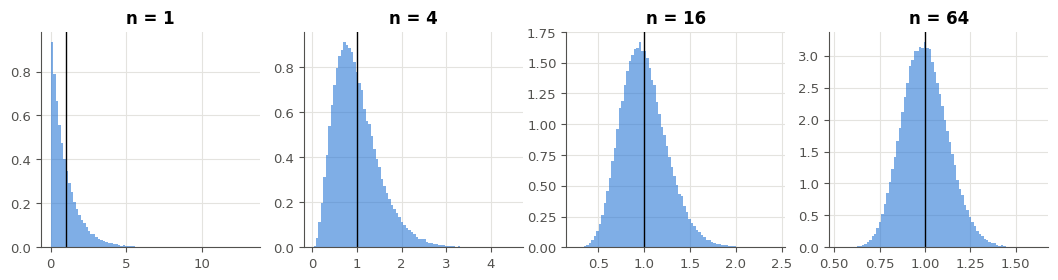

In [29]:
rng_22 = np.random.default_rng(22)
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, n in zip(axes, [1, 4, 16, 64]):
    means = rng_22.exponential(1.0, (100_000, n)).mean(axis=1)    # 100 000 means of n values, mean 1, std 1
    ax.hist(means, bins=80, density=True, alpha=0.6)
    ax.axvline(1, color="black", linewidth=1)
    ax.set_title(f"n = {n}")
    print(f"n = {n:2d} : moyenne {means.mean():.3f} · écart-type {means.std():.3f} · médiane {np.median(means):.3f}")
plt.show()

**Après l'expérience**, dans ta copie : explique chaque résultat avec la fiche ($\mathbb{E}[\bar{X}_n]$, $\sigma(\bar{X}_n)$, le théorème central limite). Pour $n = 64$, la cloche est-elle parfaitement symétrique ? Que deviennent la médiane et la moyenne des moyennes quand $n$ grandit ?

💡 a) L'écart-type des moyennes vaut $\frac{\sigma}{\sqrt{n}}$ : 4 fois plus de valeurs le divisent par 2 (0,5 puis 0,25). b) $\mathbb{E}[\bar{X}_n] = \mu = 1$ pour tout $n$ : le centre ne bouge pas, seule la largeur diminue. c) Pour $n = 1$, l'histogramme est celui de la loi elle-même, la densité $e^{-x}$ : un maximum en 0 et une longue queue à droite ; le théorème central limite ne dit rien pour $n = 1$. d) La médiane de la loi exponentielle vaut $\ln 2 \approx 0{,}69 < 1$ (M02a) : la longue queue tire la moyenne vers la droite. Quand $n$ grandit, la médiane des moyennes se rapproche de 1 (0,92 pour $n = 4$, 0,996 pour $n = 64$) : la distribution devient symétrique, mais garde une légère asymétrie pour $n = 64$.

### Ex M02c.23 — Couverture : 95 % des intervalles contiennent-ils la vraie moyenne ? 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer par simulation la couverture de l'intervalle $\bar{x} \pm z\,\frac{s}{\sqrt{n}}$, et voir quand elle s'éloigne de 95 %.  
**Prérequis :** fiche §5 et §7 · **Parcours :** C, E

La **couverture** d'une méthode d'intervalle de confiance est la proportion des échantillons pour lesquels l'intervalle contient la vraie valeur (fiche §7). La cellule fournie tire, une fois pour toutes, trois paquets de 10 000 échantillons (une ligne par échantillon) : `NORMAL_20` (20 valeurs de $\mathcal{N}(10, 3^2)$), `EXPO_10` et `EXPO_100` (10 et 100 valeurs d'une loi exponentielle d'espérance 2).

Écris `coverage(samples, true_mean, z=1.96)`, qui calcule pour **chaque ligne** l'intervalle $\bar{x} \pm z\,\frac{s}{\sqrt{n}}$ (avec $s$ divisé par $n - 1$) et renvoie la proportion des lignes dont l'intervalle contient `true_mean`. Vectorise : `samples.mean(axis=1)` et `samples.std(axis=1, ddof=1)` traitent toutes les lignes d'un coup.

Puis calcule (3 décimales) :
- a) la couverture à 95 % pour `NORMAL_20` ;
- b) pour `EXPO_10` ;
- c) pour `EXPO_100` ;
- d) la couverture pour `NORMAL_20` avec $z = 1{,}645$ ;
- e) la couverture pour `NORMAL_20` avec le quantile de Student à 19 degrés de liberté, `stats.t.ppf(0.975, 19)`, à la place de 1,96.

Dans ta copie : l'aléa d'une proportion estimée sur 10 000 échantillons est d'environ $\sqrt{\frac{0{,}95 \times 0{,}05}{10\,000}} \approx 0{,}002$. Lesquelles de ces couvertures sont nettement sous 0,95 ? Pourquoi b) est-elle la plus basse, et pourquoi c) remonte-t-elle ? Que corrige e) ?

In [30]:
rng_23 = np.random.default_rng(23)
NORMAL_20 = rng_23.normal(10, 3, (10_000, 20))         # 10 000 samples of 20 values of N(10, 3²): true mean 10
EXPO_10 = rng_23.exponential(2.0, (10_000, 10))        # 10 000 samples of 10 values, exponential law: true mean 2
EXPO_100 = rng_23.exponential(2.0, (10_000, 100))      # 10 000 samples of 100 values of the same law

In [31]:
def coverage(samples, true_mean, z=1.96):
    """The share of the rows of samples whose interval mean ± z s/√n (s with ddof=1) contains true_mean."""
    samples = np.asarray(samples, dtype=float)
    means = samples.mean(axis=1)
    half = z * samples.std(axis=1, ddof=1) / math.sqrt(samples.shape[1])
    return float(np.mean((means - half <= true_mean) & (true_mean <= means + half)))


coverage_a = coverage(NORMAL_20, 10)
coverage_b = coverage(EXPO_10, 2)
coverage_c = coverage(EXPO_100, 2)
coverage_d = coverage(NORMAL_20, 10, z=1.645)
coverage_e = coverage(NORMAL_20, 10, z=stats.t.ppf(0.975, 19))
print(coverage_a, coverage_b, coverage_c, coverage_d, coverage_e, "· Student quantile:", stats.t.ppf(0.975, 19))

0.9329 0.87 0.9406 0.8772 0.947 · Student quantile: 2.093024054408263


In [32]:
wbm.record("M02c.23a", 0.9329, decimals=3,
           mistakes={"l'écart-type s divise par n − 1 (ddof=1)": 0.9246,
                     "l'intervalle utilise l'erreur type s/√n, pas l'écart-type s des données": 1.0})
wbm.record("M02c.23b", 0.87, decimals=3,
           mistakes={"l'écart-type s divise par n − 1 (ddof=1)": 0.856})
wbm.record("M02c.23c", 0.9406, decimals=3)
wbm.record("M02c.23d", 0.8772, decimals=3,
           mistakes={"l'écart-type s divise par n − 1 (ddof=1)": 0.868})
wbm.record("M02c.23e", 0.947, decimals=3,
           mistakes={"l'écart-type s divise par n − 1 (ddof=1)": 0.9417})

WBM_ANSWER {"coarse_any": {"0": ["24b93fb8eef8c5d17e3d672278bd1f369fd9cb08411f2d04a9026463b0bf1d20"], "1": ["47829e14e188b78282ab58794679742d4839f2c878362ae2a99ca871b6cf8f8c"]}, "decimals": 3, "hash": "993588f9e12e16600e9381a542cfbf4d1fbb0959dcbb9e15834d2c074566ee3f", "hash_coarse": "b81a14e077d4fe042405ed4fd460bd9cbab5872e907c26054ecf3073a2472d5f", "id": "M02c.23a", "kind": "float", "magnitude": -1, "mistakes": {"54651bb6d7a17b513cf8551d1167296ad9a87acafacce5eca928fb53b20c4b85": "l'intervalle utilise l'erreur type s/√n, pas l'écart-type s des données", "7bef620e659eea716a2e3057f5b417163e1ec73042b2e3d7bd1c5ecb37f25eed": "l'écart-type s divise par n − 1 (ddof=1)"}, "sign": 1}
📝 Ex M02c.23a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["29cf06c9f18e9db078a966d16da0e59cc34e7fe2003815256fcfdc1cf4a337b6"], "1": ["3f236857f7c90a1304766ec3c3f3161f69fabfbb1991098e4de369d64baf9fbe"]}, "decimals": 3, "hash": "d92be06d1e35c44e4ef5849eb0e445752c1c576eb5a0330ef2d68ba5

💡 a) 0,933 : même pour des données normales, 1,96 est un peu trop petit avec 20 valeurs, parce que $s$ varie d'un échantillon à l'autre. b) 0,870 : avec 10 valeurs d'une loi très asymétrique, la moyenne n'est pas encore normale, et $s$ est souvent trop petit quand $\bar{x}$ l'est (les deux dépendent des rares grandes valeurs). c) 0,941 : avec 100 valeurs, le théorème central limite fait son effet. d) 0,877, proche des 90 % annoncés (même léger déficit qu'en a). e) 0,947 : le quantile de Student (2,093) corrige l'incertitude de $s$ pour des données normales ; il ne corrigerait pas l'asymétrie de b). Le défi M02c.28 cherche un intervalle exact pour ce cas.

### Ex M02c.24 — Grande dimension : le cube dont le centre est vide 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer par Monte-Carlo la part du cube occupée par la boule inscrite et par une fine couche près du bord, et voir où la simulation cesse d'être utile.  
**Prérequis :** fiche §4 et §9 · **Parcours :** C

La cellule fournie tire 100 000 points uniformes dans le cube $[-1 ; 1]^d$ pour $d = 2, 3, 10, 20$ (le dictionnaire `CUBES_24`, une ligne par point). Écris :
- `ball_fraction(points)` : la proportion des points dans la boule de rayon 1 centrée en 0 ($x_1^2 + \cdots + x_d^2 \le 1$) ;
- `border_fraction(points, eps=0.05)` : la proportion des points à moins de `eps` du bord du cube, c'est-à-dire dont **au moins une** coordonnée dépasse $1 - \varepsilon$ en valeur absolue ;
- `exact_ball_fraction(d)` : la valeur exacte, $\frac{\pi^{d/2}}{\Gamma(d/2 + 1)\,2^d}$ (la formule admise par la fiche ; `math.gamma` calcule $\Gamma$).

Puis calcule :
- a) `ball_fraction` pour $d = 2$ (3 décimales) ;
- b) pour $d = 3$ (3 décimales) ;
- c) pour $d = 10$ (4 décimales) ;
- d) `border_fraction` pour $d = 20$ (3 décimales) ;
- e) `exact_ball_fraction(10)` (5 décimales) ;
- f) le **nombre** de points de `CUBES_24[20]` dans la boule (un entier).

Dans ta copie : compare a), b), d) aux valeurs exactes de la fiche ($\frac{\pi}{4}$, $\frac{\pi}{6}$, $1 - 0{,}95^{20}$). L'écart entre c) et e) est-il normal, compte tenu de l'erreur type d'une proportion ? Combien de points faudrait-il, en moyenne, pour en voir **un seul** dans la boule en dimension 20 (`exact_ball_fraction(20)`) ? Que dit f) des limites de Monte-Carlo pour un événement très rare ?

In [33]:
rng_24 = np.random.default_rng(24)
CUBES_24 = {d: rng_24.uniform(-1, 1, (100_000, d)) for d in (2, 3, 10, 20)}   # 100 000 points in [−1, 1]^d

In [34]:
def ball_fraction(points):
    """The share of the points (one per row) inside the ball of radius 1 centred at 0."""
    return float(np.mean(np.sum(np.asarray(points) ** 2, axis=1) <= 1))


def border_fraction(points, eps=0.05):
    """The share of the points with at least one coordinate beyond 1 − eps in absolute value."""
    return float(np.mean(np.max(np.abs(np.asarray(points)), axis=1) > 1 - eps))


def exact_ball_fraction(d):
    """The volume of the unit ball of dimension d divided by the volume 2^d of the cube [−1, 1]^d."""
    return math.pi ** (d / 2) / math.gamma(d / 2 + 1) / 2 ** d


answer_M02c_24a = ball_fraction(CUBES_24[2])
answer_M02c_24b = ball_fraction(CUBES_24[3])
answer_M02c_24c = ball_fraction(CUBES_24[10])
answer_M02c_24d = border_fraction(CUBES_24[20])
answer_M02c_24e = exact_ball_fraction(10)
answer_M02c_24f = int(np.sum(np.sum(CUBES_24[20] ** 2, axis=1) <= 1))
print(answer_M02c_24a, math.pi / 4, "·", answer_M02c_24b, math.pi / 6, "·", answer_M02c_24c, answer_M02c_24e)
print(answer_M02c_24d, 1 - 0.95 ** 20, "·", answer_M02c_24f, "· d = 20:", exact_ball_fraction(20),
      "· points for one inside:", 1 / exact_ball_fraction(20))

0.78493 0.7853981633974483 · 0.52423 0.5235987755982988 · 0.0023 0.00249039457019272
0.63911 0.6415140775914581 · 0 · d = 20: 2.461136950494199e-08 · points for one inside: 40631627.58168329


In [35]:
wbm.record("M02c.24a", 0.78493, decimals=3,
           mistakes={"la boule de rayon 1 : la somme des carrés des coordonnées est au plus 1, pas 1/4": 0.19629})
wbm.record("M02c.24b", 0.52423, decimals=3)
wbm.record("M02c.24c", 0.0023, decimals=4)
wbm.record("M02c.24d", 0.63911, decimals=3,
           mistakes={"près du bord dès qu'**au moins une** coordonnée dépasse 1 − eps : le maximum des valeurs absolues, "
                     "pas le minimum": 0.0})
wbm.record("M02c.24e", 0.002490395, decimals=5,
           mistakes={"divise le volume de la boule par celui du cube, 2^d": 2.550164040})
wbm.record("M02c.24f", 0)

WBM_ANSWER {"coarse_any": {"0": ["5c5fa4e7c90115815e3a35edd56a568ea499a7452beba63223fca22f3febf48d"], "1": ["658f63568727f6acd3fbcd0ed7680a3fbf43eb7bd48ebd3f2fe90c04b137cd43"]}, "decimals": 3, "hash": "a95a2427c3519db689ace086d8d09765f532d75073d35c0649e0f10932d9f752", "hash_coarse": "336f88b7d081701bba3eff3b9fdaa727c68ef80f5091cf759ca2f121bbed9e21", "id": "M02c.24a", "kind": "float", "magnitude": -1, "mistakes": {"e7edeaf17f4f144c728b6331485b472614632c2f3a9f8eed12fa8f10b9265838": "la boule de rayon 1 : la somme des carrés des coordonnées est au plus 1, pas 1/4"}, "sign": 1}
📝 Ex M02c.24a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["eb5a1e3bc5ba497a917f233476bd178c15cfcbb20b05f7ec5862994d8ad59057"], "1": ["74f7d2cfe0128a5b10247c66a670b8224ec5d264c8dc1859c447cec263f8f1b1"]}, "decimals": 3, "hash": "2413520924c83e85eec567c9e35569788f37786b69adc49c846327a3ad1c5f5d", "hash_coarse": "e09a61d6c97bd74eb8107baf38a32c5e4eb721ccafd0da57a738e7242dfb166c", "id": "M0

💡 a) 0,785 et b) 0,524, pour $\frac{\pi}{4} \approx 0{,}7854$ et $\frac{\pi}{6} \approx 0{,}5236$. c) 0,0023 pour 0,00249 : 230 points sur 100 000 au lieu de 249 attendus ; l'erreur type d'une proportion $p$ sur $N$ points vaut $\sqrt{\frac{p(1 - p)}{N}} \approx 0{,}00016$, et l'écart (0,00019) en fait à peine plus d'une. d) 0,639 pour $1 - 0{,}95^{20} \approx 0{,}6415$. f) Aucun point en dimension 20 : la boule occupe $2{,}5 \times 10^{-8}$ du cube, il faudrait en moyenne 40 millions de points pour en voir un. Monte-Carlo estime bien une proportion de l'ordre de 0,1 à 0,9 ; pour un événement très rare, son erreur **relative** $\frac{1}{\sqrt{Np}}$ explose, et il faut d'autres méthodes (l'échantillonnage préférentiel, chapitre 28 de workbookIA).

### Ex M02c.25 — Voir le théorème central limite : histogrammes et densité normale 🎨 ★ ⏱️ 20 min
**Objectif :** tracer les histogrammes des moyennes d'échantillons pour plusieurs tailles, avec la densité normale que prévoit le théorème central limite.  
**Prérequis :** fiche §5 ; R0 (matplotlib) · **Parcours :** C

Écris `draw_clt(axes, draw, mu, sigma, ns, repeats=20_000, seed=0)`, qui dessine, pour chaque taille $n$ de la liste `ns` et dans l'axe correspondant de `axes` :
- l'**histogramme** des `repeats` moyennes de $n$ tirages (ta fonction `mymath.estimation.sample_means(draw, n, repeats, seed)`, ou ton propre code), avec `density=True` pour qu'il ait une aire de 1, comme une densité ;
- la **densité normale** prévue par le théorème central limite, $\mathcal{N}\big(\mu, \frac{\sigma^2}{n}\big)$, tracée sur une grille de valeurs (`stats.norm(mu, sigma / math.sqrt(n)).pdf(grid)`, avec `grid` couvrant au moins $\mu \pm 4\frac{\sigma}{\sqrt{n}}$) ;
- un titre qui indique $n$.

Puis trace-la pour la loi exponentielle d'espérance 1 (`EXPO_DRAW`, $\mu = \sigma = 1$) et `NS_25` $= [1, 2, 10, 50]$.

Dans ta copie : pour quel $n$ la densité normale te semble-t-elle décrire correctement l'histogramme ? Où l'écart se voit-il le plus pour $n = 10$ : au centre ou dans les queues ? Pourquoi la courbe de $n = 1$ est-elle si loin de l'histogramme ?

In [36]:
EXPO_DRAW = lambda rng, n: rng.exponential(1.0, n)     # the exponential law of mean 1 and standard deviation 1
NS_25 = [1, 2, 10, 50]

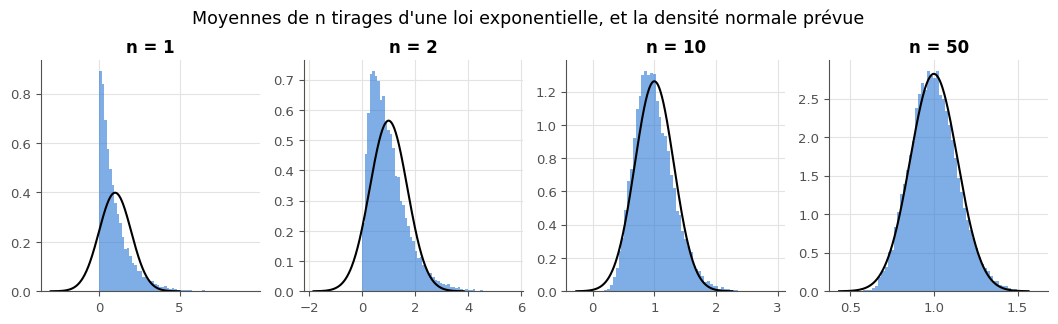

In [37]:
def draw_clt(axes, draw, mu, sigma, ns, repeats=20_000, seed=0):
    """For each n of ns, in the matching axis: the histogram (density=True) of repeats means of n draws, the normal
    density N(mu, sigma²/n), and a title with n."""
    for ax, n in zip(axes, ns):
        means = mymath.estimation.sample_means(draw, n, repeats, seed)
        ax.hist(means, bins=60, density=True, alpha=0.6)
        width = sigma / math.sqrt(n)
        grid = np.linspace(mu - 4 * width, mu + 4 * width, 300)
        ax.plot(grid, stats.norm(mu, width).pdf(grid), color="black", linewidth=1.5)
        ax.set_title(f"n = {n}")


fig, axes = plt.subplots(1, 4, figsize=(13, 3))
draw_clt(axes, EXPO_DRAW, 1.0, 1.0, NS_25)
fig.suptitle("Moyennes de n tirages d'une loi exponentielle, et la densité normale prévue", y=1.05)
plt.show()

**Vérifications automatiques** (sur une autre loi, uniforme ; la figure elle-même se juge à l'œil).

In [38]:
with checked("M02c.25 vérifications"):
    problems = []
    uniform_draw = lambda rng, n: rng.random(n)            # another law: uniform on [0, 1], mean 0.5, std √(1/12)
    mu_t, sigma_t = 0.5, math.sqrt(1 / 12)
    fig, axes = plt.subplots(1, 2, figsize=(8, 3))
    try:
        created = drawn(draw_clt, axes, uniform_draw, mu_t, sigma_t, [1, 9], 4_000)
    finally:
        plt.close(fig)                                     # only the checks below are shown here
    if created:
        problems.append("draw_clt ouvre sa propre figure : dessine dans les axes reçus")
    else:
        for ax, n in zip(axes, [1, 9]):
            bars = [p for p in ax.patches if p.get_height() > 0]
            area = sum(p.get_width() * p.get_height() for p in bars)
            if not bars or abs(area - 1) > 0.02:
                problems.append(f"n = {n} : l'histogramme doit avoir une aire de 1 (density=True)")
                continue
            centre = sum((p.get_x() + p.get_width() / 2) * p.get_width() * p.get_height() for p in bars) / area
            if abs(centre - mu_t) > 0.05:
                problems.append(f"n = {n} : l'histogramme doit être celui des moyennes de n tirages, centré sur mu")
            spread = math.sqrt(sum((p.get_x() + p.get_width() / 2 - centre) ** 2 * p.get_width() * p.get_height()
                                   for p in bars) / area)
            if abs(spread / (sigma_t / math.sqrt(n)) - 1) > 0.15:
                problems.append(f"n = {n} : la largeur de l'histogramme doit être celle des moyennes de n tirages, "
                                "sigma / √n")
            lines = [line for line in ax.get_lines() if len(line.get_xdata()) > 20]
            if not lines:
                problems.append(f"n = {n} : il manque la courbe de la densité normale (ax.plot sur une grille)")
                continue
            xs, ys = (np.asarray(lines[0].get_xdata(), dtype=float), np.asarray(lines[0].get_ydata(), dtype=float))
            peak_x, peak_y = xs[np.argmax(ys)], ys.max()
            expected = 1 / (sigma_t / math.sqrt(n) * math.sqrt(2 * math.pi))
            if abs(peak_x - mu_t) > 0.02 * (1 + sigma_t):
                problems.append(f"n = {n} : le sommet de la densité normale doit être en mu (il est en {peak_x:.3f})")
            if abs(peak_y / expected - 1) > 0.02:
                problems.append(f"n = {n} : la densité normale doit avoir l'écart-type sigma / √n (sa hauteur au "
                                "sommet n'est pas la bonne)")
            if str(n) not in ax.get_title():
                problems.append(f"n = {n} : le titre de chaque axe doit indiquer n")
    if problems:
        print("❌ Ex M02c.25 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M02c.25 : des histogrammes de moyennes, d'aire 1, bien centrés, avec la bonne densité normale.")

✅ Ex M02c.25 : des histogrammes de moyennes, d'aire 1, bien centrés, avec la bonne densité normale.


💡 Pour $n = 1$, l'histogramme est la densité $e^{-x}$ elle-même, et la cloche $\mathcal{N}(1, 1)$ n'a rien à voir avec elle (elle donne même du poids aux valeurs négatives, impossibles). Pour $n = 2$ et $n = 10$, l'histogramme reste penché : son sommet est à gauche de 1, sa queue droite plus longue que la gauche. Pour $n = 50$, la cloche le décrit bien au centre ; l'écart restant est dans les queues (la queue droite reste un peu plus épaisse). Le théorème central limite est une approximation **au centre** d'abord.

## Partie C · Erreurs classiques, tests et défi

Fiche §4 à §7. Quatre erreurs d'intervalle à trouver, le test d'une fonction aléatoire, puis un intervalle exact pour dix valeurs.

### Ex M02c.26 — Chasse à l'erreur : un intervalle de confiance mal calculé 🐛 ★ ⏱️ 15 min
**Objectif :** repérer les erreurs classiques d'une erreur type ou d'un intervalle de confiance dans du code, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §7 · **Parcours :** C

Une collègue a mesuré $n = 25$ fois la durée d'un traitement : moyenne `mean = 50`, écart-type `s = 10` (divisé par $n - 1$). Elle a aussi évalué un modèle : accuracy `acc = 0.8` sur `n_test = 400` exemples. Voici ses six lignes de code, chacune avec un commentaire qui dit ce qu'elle veut calculer. Quatre lignes sont fausses. **Sans exécuter de code**, trouve-les.

```python
half_A = 1.96 * s / n                                # (A) half-width of the 95 % interval of the mean
half_B = 1.96 * s ** 2 / math.sqrt(n)                # (B) half-width of the 95 % interval of the mean
half_C = 1.645 * s / math.sqrt(n)                    # (C) half-width of the 90 % interval of the mean
half_D = 1.96 * s / math.sqrt(n)                     # (D) half-width of the 99 % interval of the mean
low_E, high_E = mean - 1.96 * s, mean + 1.96 * s     # (E) the 95 % confidence interval of the mean
se_F = math.sqrt(acc * (1 - acc) / n_test)           # (F) standard error of the accuracy
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire : la demi-largeur demandée pour (A) à (E), l'erreur type pour (F) (une liste de 6 nombres, 3 décimales).

Dans ta copie : pour chaque ligne fausse, quelle confusion a été faite ? L'intervalle de (E) a-t-il quand même un sens ?

In [39]:
answer_M02c_26a = "ABDE"
half_95 = stats.norm.ppf(0.975) * 10 / math.sqrt(25)
answer_M02c_26b = [half_95, half_95, stats.norm.ppf(0.95) * 10 / math.sqrt(25), stats.norm.ppf(0.995) * 10 / math.sqrt(25),
                   half_95, math.sqrt(0.8 * 0.2 / 400)]
print(answer_M02c_26a, [round(float(v), 3) for v in answer_M02c_26b])

ABDE [3.92, 3.92, 3.29, 5.152, 3.92, 0.02]


In [40]:
wbm.record("M02c.26a", "ABDE",
           mistakes={"il manque une ligne fautive : vérifie la puissance de n dans chaque erreur type": "BDE",
                     "il manque une ligne fautive : vérifie que chaque formule multiplie bien un écart-type, et pas une autre grandeur": "ADE",
                     "il manque une ligne fautive : vérifie que chaque quantile correspond au niveau annoncé": "ABE",
                     "il manque une ligne fautive : vérifie que chaque intervalle porte bien sur la moyenne, pas sur les valeurs elles-mêmes": "ABD",
                     "une ligne de trop : la ligne (C) est correcte ; relis ce qu'elle fait": "ABCDE",
                     "une ligne de trop : la ligne (F) est correcte ; relis ce qu'elle fait": "ABDEF",
                     "la ligne (C) est correcte, et il manque une ligne fautive : vérifie la puissance de n dans chaque erreur type": "BCDE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : vérifie la puissance de n dans chaque erreur type": "BDEF",
                     "la ligne (C) est correcte, et il manque une ligne fautive : vérifie que chaque formule multiplie bien un écart-type, et pas une autre grandeur": "ACDE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : vérifie que chaque formule multiplie bien un écart-type, et pas une autre grandeur": "ADEF",
                     "la ligne (C) est correcte, et il manque une ligne fautive : vérifie que chaque quantile correspond au niveau annoncé": "ABCE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : vérifie que chaque quantile correspond au niveau annoncé": "ABEF",
                     "la ligne (C) est correcte, et il manque une ligne fautive : vérifie que chaque intervalle porte bien sur la moyenne, pas sur les valeurs elles-mêmes": "ABCD",
                     "la ligne (F) est correcte, et il manque une ligne fautive : vérifie que chaque intervalle porte bien sur la moyenne, pas sur les valeurs elles-mêmes": "ABDF",
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "B", "D", "E", "AB", "AD", "AE", "BD", "BE", "DE"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"C", "F", "AC", "AF", "BC", "BF", "CD", "CE", "CF", "DF", "EF", "ABC", "ABF", "ACD", "ACE", "ACF", "ADF", "AEF", "BCD", "BCE", "BCF", "BDF", "BEF", "CDE", "CDF", "CEF", "DEF", "ABCF", "ACDF", "ACEF", "BCDF", "BCEF", "CDEF", "ABCDF", "ABCEF", "ACDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDEF"}})
wbm.record("M02c.26b", [3.919927969, 3.919927969, 3.289707254, 5.151658654, 3.919927969, 0.02], decimals=3,
           mistakes={"ce sont les valeurs des lignes ; donne les bonnes valeurs de ce que disent les commentaires":
                         [0.784, 39.2, 3.29, 3.92, 19.6, 0.02],
                     "(D) : à 99 %, le quantile n'est pas 1,96": [3.919927969, 3.919927969, 3.289707254, 3.919927969,
                                                                  3.919927969, 0.02]})

WBM_ANSWER {"hash": "b54be6b398851e0c118301e31b463c01c1588b1d2af2c264f69c9f8980a8651c", "id": "M02c.26a", "kind": "str", "mistakes": {"0b8e4063b34a875d4aa081fb73a989699b530a6c2e526fe2b825932250e4188c": "la ligne (C) est correcte, et il manque une ligne fautive : vérifie que chaque formule multiplie bien un écart-type, et pas une autre grandeur", "0ba5e4af5572ae2b8fcadbce569e7a327c6875d0b633917e35f3a8336d63ab1e": "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple", "0cfc6c2dd1543ebd91e2869a017313c145edafacab5570a9fec55b34998a3551": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "13f51eb43005e898e18fa8d1f59947d28e54bda945d58c4fc63fb4c4c0ea156a": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "16858d5ec3a74b783741c883e615d536747f0c9a19790b07064c6a7c4162dac3": "il manque des lignes fautives, et des lignes que tu

💡 (A) divise par $n$ au lieu de $\sqrt{n}$ (0,784 au lieu de 3,92). (B) multiplie la **variance** $s^2$ au lieu de l'écart-type (39,2). (D) garde 1,96 pour un niveau de 99 % : il faut 2,576, d'où 5,152. (E) oublie le $\sqrt{n}$ : $[30{,}4 ; 69{,}6]$ contient environ 95 % des **durées** (si elles sont à peu près normales), pas la moyenne avec 95 % de confiance ; c'est un autre objet, un intervalle de **prédiction** d'une valeur. (C) et (F) sont justes : 1,645 est le quantile de 90 %, et $\sqrt{\frac{0{,}8 \times 0{,}2}{400}} = 0{,}02$.

### Ex M02c.27 — Tester une fonction aléatoire : une tolérance en erreurs types 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire le test d'une fonction aléatoire avec une tolérance fixée en erreurs types, ni trop étroite (test instable) ni trop large (bugs invisibles).  
**Prérequis :** fiche §4 et §7 ; Ex M02c.18 · **Parcours :** C

Comment tester une fonction dont le résultat est aléatoire ? Comparer à la valeur exacte avec `==` échoue toujours ; avec une tolérance prise au hasard (`abs(x - pi) < 0.1`), le test laisse passer des bugs, ou échoue sans bug (on dit qu'il est **instable**, *flaky*). La bonne tolérance se compte en **erreurs types** : une estimation juste tombe à moins de $4$ erreurs types de la vraie valeur, sauf avec une probabilité de l'ordre de $10^{-4}$ (fiche §5).

La cellule fournie définit `estimate_pi(n, rng)`, qui estime $\pi$ par Monte-Carlo (4 fois la proportion de $n$ points uniformes du carré $[0 ; 1]^2$ tombés dans le quart de disque de rayon 1), et deux copies fausses. Écris :
- `pi_standard_error(n)` : l'erreur type de `estimate_pi` pour $n$ points, $4\sqrt{\frac{p(1 - p)}{n}}$ avec $p = \frac{\pi}{4}$ (pourquoi 4 ?) ;
- `pi_test(estimate, seed, n=100_000, k=4)` : renvoie `True` si `estimate(n, np.random.default_rng(seed))` est à moins de `k` erreurs types de $\pi$, `False` sinon.

La vérification lance ton test sur la bonne fonction et sur la copie fausse au rayon de 0,99, pour 100 graines : il doit accepter la bonne fonction **toutes** les fois, et refuser la fausse **toutes** les fois.

Dans ta copie : que se passerait-il avec `k=1` ? Avec `k=50` ? Pourquoi la fonction décalée de $+0{,}002$ passe-t-elle presque toujours, et combien de points faudrait-il pour l'attraper ?

In [41]:
def estimate_pi(n, rng):
    """Monte Carlo estimate of π: 4 × the share of n uniform points of [0, 1]² inside the quarter disc."""
    points = rng.random((n, 2))
    return 4 * float(np.mean(np.sum(points ** 2, axis=1) <= 1))


def estimate_pi_shrunk(n, rng):
    """A buggy copy: the quarter disc has a radius of 0.99 instead of 1 (an error of about 2 %)."""
    points = rng.random((n, 2))
    return 4 * float(np.mean(np.sum(points ** 2, axis=1) <= 0.99 ** 2))


def estimate_pi_slightly_off(n, rng):
    """A buggy copy whose error (+0.002) is smaller than one standard error for n = 100 000."""
    return estimate_pi(n, rng) + 0.002

In [42]:
def pi_standard_error(n):
    """The standard error of estimate_pi for n points."""
    p = math.pi / 4                          # the probability that one point falls inside the quarter disc
    return 4 * math.sqrt(p * (1 - p) / n)    # estimate_pi multiplies a proportion by 4


def pi_test(estimate, seed, n=100_000, k=4):
    """True if estimate(n, rng) is within k standard errors of π, with rng = np.random.default_rng(seed)."""
    return abs(estimate(n, np.random.default_rng(seed)) - math.pi) <= k * pi_standard_error(n)


print("standard error for 100 000 points:", pi_standard_error(100_000),
      "· bias of the shrunk copy:", math.pi * (0.99 ** 2 - 1))

standard error for 100 000 points: 0.005193039777692652 · bias of the shrunk copy: -0.06251769380643697


In [43]:
with checked("M02c.27 vérifications"):
    problems = []
    se = pi_standard_error(100_000)
    if not isinstance(se, (int, float)) or abs(se - 4 * math.sqrt(math.pi / 4 * (1 - math.pi / 4) / 100_000)) > 1e-6:
        problems.append("pi_standard_error(n) : 4 × √(p (1 − p) / n), avec p = π/4 la probabilité d'un point dans le "
                        "quart de disque")
    passed = [bool(pi_test(estimate_pi, seed)) for seed in range(100)]
    caught = [not pi_test(estimate_pi_shrunk, seed) for seed in range(100)]
    print(f"la bonne fonction passe ton test pour {sum(passed)} graines sur 100 ; la fonction fausse est attrapée "
          f"{sum(caught)} fois sur 100")
    if sum(passed) < 100:
        problems.append("ton test échoue sur la bonne fonction pour certaines graines : la tolérance est trop étroite "
                        "(un test qui échoue sans bug est un test « instable », flaky)")
    if sum(caught) < 100:
        problems.append("ton test laisse passer la fonction au rayon de 0,99 : la tolérance est trop large")
    if problems:
        print("❌ Ex M02c.27 : à revoir : " + " ; ".join(problems) + ".")
    else:
        slight = sum(not pi_test(estimate_pi_slightly_off, seed) for seed in range(100))
        print(f"✅ Ex M02c.27 : une tolérance juste. (La fonction décalée de +0,002 n'est attrapée que {slight} fois sur "
              "100 : un écart plus petit qu'une erreur type est invisible pour un seul tirage.)")

la bonne fonction passe ton test pour 100 graines sur 100 ; la fonction fausse est attrapée 100 fois sur 100
✅ Ex M02c.27 : une tolérance juste. (La fonction décalée de +0,002 n'est attrapée que 0 fois sur 100 : un écart plus petit qu'une erreur type est invisible pour un seul tirage.)


💡 L'erreur type vaut $4\sqrt{\frac{0{,}785 \times 0{,}215}{100\,000}} \approx 0{,}0052$ (le 4 vient de ce que l'estimation est 4 fois une proportion, et $\sigma(4Y) = 4\sigma(Y)$). La copie au rayon de 0,99 a un biais de $\pi(0{,}99^2 - 1) \approx -0{,}063$, soit 12 erreurs types : toujours attrapée. Avec `k=1`, la bonne fonction échouerait environ une fois sur trois ($2(1 - \Phi(1)) \approx 0{,}32$) ; avec `k=50`, même la copie fausse passerait. Le décalage de 0,002 vaut 0,4 erreur type : pour l'attraper à 4 erreurs types, il faudrait au moins $4\,\text{SE} < 0{,}002$, soit $n$ de l'ordre de 11 millions de points ($\text{SE}$ en $\frac{1}{\sqrt{n}}$), et davantage pour l'attraper à coup sûr. Les tests de `mymath` qui portent sur des simulations, comme celui du biais de $S_n^2$, sont construits ainsi.

### Ex M02c.28 — Défi : un intervalle à 95 % avec dix valeurs d'une loi asymétrique 🏆 ★★★ ⏱️ 30 min
**Objectif :** construire un intervalle de confiance à 95 % pour la moyenne d'une loi exponentielle à partir de dix valeurs seulement, avec une couverture juste et une largeur raisonnable.  
**Prérequis :** fiche §5 à §7 ; Ex M02c.23 · **Parcours :** C

Avec 10 valeurs d'une loi exponentielle, l'intervalle $\bar{x} \pm 1{,}96\,\frac{s}{\sqrt{n}}$ ne couvre la vraie moyenne qu'environ 87 fois sur 100 (M02c.23), et le quantile de Student ne suffit pas. Écris `interval_10(sample)`, qui reçoit un array de **10 valeurs** tirées d'une loi exponentielle de moyenne $\mu$ **inconnue**, et renvoie un intervalle `(low, high)` pour $\mu$. **Objectifs**, mesurés sur les 4 500 échantillons de la cellule fournie (1 500 pour chacune des moyennes 0,5, 3 et 40, que ta fonction ne connaît pas) :
1. la couverture est entre 0,94 et 0,96, et entre 0,93 et 0,97 pour chaque moyenne ;
2. la largeur moyenne des intervalles est au plus $1{,}6\,\mu$ ;
3. moins de 20 secondes pour les 4 500 intervalles.

Tous les outils sont permis (NumPy, SciPy, une simulation). Pistes (`04_indices.md` les détaille) :
- le bootstrap des percentiles (fiche §7) : tente-le, et regarde quel objectif il manque ;
- une remarque clé : si $X$ suit une loi exponentielle de moyenne $\mu$, alors $\frac{X}{\mu}$ suit la loi exponentielle de moyenne 1. Que peux-tu en dire de la loi de $\frac{\bar{X}}{\mu}$ ? Dépend-elle de $\mu$ ? Comment connaître ses quantiles, même sans formule ?

Dans ta copie : quelle méthode as-tu retenue ? Pourquoi ton intervalle n'est-il pas symétrique autour de $\bar{x}$ ? Pourquoi le bootstrap des percentiles couvre-t-il mal avec 10 valeurs ?

In [44]:
rng_28 = np.random.default_rng(28)
SCALES_28 = np.repeat([0.5, 3.0, 40.0], 1500)                              # the true means μ, unknown to you
SAMPLES_28 = rng_28.exponential(1.0, (4500, 10)) * SCALES_28[:, None]      # 4 500 samples of 10 values

In [45]:
# The law of mean(X) / μ is the same for every μ (it is the mean of 10 exponentials of mean 1): simulate it once,
# take its quantiles q_low and q_high, and invert q_low ≤ mean / μ ≤ q_high into mean / q_high ≤ μ ≤ mean / q_low.
PIVOT_MEANS = np.random.default_rng(2028).exponential(1.0, (200_000, 10)).mean(axis=1)
Q_LOW, Q_HIGH = np.percentile(PIVOT_MEANS, [2.5, 97.5])


def interval_10(sample):
    """A 95 % confidence interval (low, high) for the mean of an exponential law, from 10 values."""
    m = float(np.mean(sample))
    return m / Q_HIGH, m / Q_LOW


exact_low, exact_high = stats.gamma(10, scale=1 / 10).ppf([0.025, 0.975])   # the exact law of mean / μ
print(f"simulated quantiles of mean/μ: {Q_LOW:.4f}, {Q_HIGH:.4f} · exact (gamma law): {exact_low:.4f}, {exact_high:.4f}")


def bootstrap_percentile(sample, resamples=2000, rng=np.random.default_rng(0)):
    """The bootstrap percentile interval, for comparison."""
    means = np.asarray(sample)[rng.integers(0, len(sample), (resamples, len(sample)))].mean(axis=1)
    return tuple(np.percentile(means, [2.5, 97.5]))


boot = np.array([bootstrap_percentile(sample) for sample in SAMPLES_28])
print("bootstrap percentile coverage:", np.mean((boot[:, 0] <= SCALES_28) & (SCALES_28 <= boot[:, 1])))

simulated quantiles of mean/μ: 0.4795, 1.7041 · exact (gamma law): 0.4795, 1.7085


bootstrap percentile coverage: 0.8602222222222222


In [46]:
wbm.record("M02c.28", True,
           mistakes={"un objectif au moins n'est pas atteint : relis les lignes ❌ et les pistes de 04_indices.md": False})

WBM_ANSWER {"hash": "2335f636c7b51936eb254e8f9d6d599319397fa222a9646c01f3358c586ff640", "id": "M02c.28", "kind": "bool", "mistakes": {"c50786586bd49c13b5d17080ef72af014088a285333f2612621e93e359305751": "un objectif au moins n'est pas atteint : relis les lignes ❌ et les pistes de 04_indices.md"}}
📝 Ex M02c.28 : réponse enregistrée (bool).


💡 Le bootstrap des percentiles couvre environ 86 fois sur 100 : avec 10 valeurs, la loi empirique n'a pas la longue queue de la vraie loi (aucune des 10 valeurs n'est très grande, le plus souvent), et ses intervalles sont trop étroits. La remarque clé : $\frac{X_i}{\mu}$ suit la loi exponentielle de moyenne 1, donc $\frac{\bar{X}}{\mu}$ a **la même loi pour tous les $\mu$** (on dit que c'est un **pivot**). On simule cette loi une fois, on lit ses quantiles $q_{0{,}025} \approx 0{,}48$ et $q_{0{,}975} \approx 1{,}71$, et $q_{0{,}025} \le \frac{\bar{X}}{\mu} \le q_{0{,}975}$ s'inverse en $\frac{\bar{X}}{q_{0{,}975}} \le \mu \le \frac{\bar{X}}{q_{0{,}025}}$, environ $[0{,}58\,\bar{x} ;\ 2{,}09\,\bar{x}]$ : un intervalle **asymétrique**, plus long vers le haut, comme la loi. La loi de $\frac{\bar{X}}{\mu}$ a d'ailleurs une formule (une loi gamma), qui donne les mêmes quantiles. Le bootstrap-t (fiche §7, idée voisine) couvre presque 95 %, mais avec des intervalles trop longs.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu résumer une série, repérer ses valeurs aberrantes, et dire ce qu'une imputation change ?
2. Sais-tu utiliser la loi des grands nombres et le théorème central limite, et calculer le biais et l'erreur quadratique d'un estimateur ?
3. Sais-tu calculer et interpréter une erreur type, un intervalle de confiance, une covariance et une corrélation ?

**La suite** : le chapitre 2 de workbookIA (hasard et statistiques de base), puis M03, les probabilités conditionnelles.